# Evaluating LLM Summaries of Financial News for Investment Research

**Research question.** How can we summarize financial news articles for investment research, and how do we measure summary quality?

**Summary of this study**

* **Data (Part 1).** Length is not the challenge: the median article has ~130 informative words, and every article fits in one model call. The challenge is **association**. 39% of the 49 articles are not primarily about the ticker they are filed under, and 22% carry no informative body (the news is only in the headline).
* **Method (Part 2).** Two approaches with the same model and the same input. **A**: a strong baseline, a ticker-aware prose summary. **B**: a structured, grounded, relevance-triaged summary, returned as schema-constrained JSON.
* **Evaluation (Part 3).** Five layers: deterministic checks, hand-labelled relevance, an LLM judge that lists unsupported claims before scoring, a position-swapped pairwise comparison, and **validation of the evaluators themselves** (repeat-run noise, injected errors, an independent review).
* **Result (Parts 4–5).** B is much more faithful and more ticker-focused, stops overstating links to the ticker, and costs no coverage. A's errors are mostly editorial speculation and facts from outside the article, stated as if the article said them. §5.1 lists the exact numbers and checks each statement automatically.
* **Recommendation.** Adopt B's design (ticker conditioning, grounding rules, relevance triage, structured output). Monitor quality with deterministic numeric checks plus a validated LLM judge, never the judge alone.

| Brief task | Where |
|:---|:---|
| 1. Exploratory Data Analysis | Part 1 |
| 2. Methodology Design | Part 2 |
| 3. Evaluation Framework | Part 3 |
| 4. Experimentation | Part 4 |
| 5. Analysis & Recommendations | Part 5 |

**How to run.** The notebook sits next to `data/`. Input: `data/input/news_articles.json` and `data/input/reviewer_ratings.csv`. Set `ANTHROPIC_API_KEY` in the environment, or in a git-ignored `.env` file. All outputs go to `data/output/`. Every LLM response is cached in `data/output/llm_cache/`, so a re-run costs nothing and every number traces back to a raw response. Without a key or cache, Part 1 still runs and Parts 4–5 are skipped.

## 0. Setup

In [110]:
import os
from pathlib import Path

# ---- Paths -------------------------------------------------------------------
INPUT_PATH = Path("data/input/news_articles.json")
REVIEW_PATH = Path("data/input/reviewer_ratings.csv")   # independent spot-check ratings (§4.4)
OUTPUT_DIR = Path("data/output")
CACHE_DIR = OUTPUT_DIR / "llm_cache"
FIG_DIR = OUTPUT_DIR / "figures"
for d in (OUTPUT_DIR, CACHE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- API key: environment variable or a local, git-ignored .env file (never hard-coded) ----
if Path(".env").exists():
    for line in Path(".env").read_text().splitlines():
        k, _, v = line.partition("=")
        if k.strip() and v.strip():
            os.environ.setdefault(k.strip(), v.strip().strip("'\""))
ANTHROPIC_API_KEY = os.environ.get("ANTHROPIC_API_KEY", "")

# ---- Models ------------------------------------------------------------------
GEN_MODEL = "claude-sonnet-5"      # summarizer
JUDGE_MODEL = "claude-opus-5-5"    # evaluator: a different, stronger model than the generator
GEN_MAX_TOKENS = 1200              # summaries are ~100 words
JUDGE_MAX_TOKENS = 4000            # claim lists can be long (1,200 truncated 19 judge replies in the first run)
WORKERS = 4                        # parallel API calls

# ---- Visual style ------------------------------------------------------------
SCHWAB_PALETTE = [
    "#071C47",  # dark navy
    "#194E81",  # medium navy
    "#0079A7",  # deep teal blue
    "#00A0DF",  # bright cyan blue
    "#6BA4B8",  # muted light blue
    "#7F7F7F",  # neutral gray
]
SCHWAB_BACKGROUND = "#F2F2F2"
SCHWAB_SECONDARY_TEXT = "#98A5AF"
FIGSIZE = (8, 4)

In [111]:
import json, re, hashlib, random, threading, time, warnings
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from typing import Literal

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pydantic import BaseModel
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

NAVY, MID_NAVY, TEAL, CYAN, LIGHT_BLUE, GRAY = SCHWAB_PALETTE
APPROACH_COLORS = {"A_simple": MID_NAVY, "B_structured": CYAN}   # most distinct pair in the palette
RELEVANCE_COLORS = {"primary": NAVY, "secondary": TEAL, "peripheral": LIGHT_BLUE, "none": "#C9D3DA"}

mpl.rcParams.update({
    "figure.figsize": FIGSIZE, "figure.dpi": 100,
    "figure.facecolor": SCHWAB_BACKGROUND, "axes.facecolor": SCHWAB_BACKGROUND, "savefig.facecolor": SCHWAB_BACKGROUND,
    "axes.edgecolor": SCHWAB_SECONDARY_TEXT, "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": SCHWAB_SECONDARY_TEXT, "ytick.color": SCHWAB_SECONDARY_TEXT,
    "xtick.labelcolor": NAVY, "ytick.labelcolor": NAVY,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": NAVY,
    "axes.labelsize": 9, "font.size": 9, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "axes.axisbelow": True,
    "lines.linewidth": 2, "patch.linewidth": 0,
})
BAR = {"edgecolor": SCHWAB_BACKGROUND, "linewidth": 2}   # thin gap between adjacent bars


def save_fig(name: str) -> None:
    """Tight layout, save to FIG_DIR, show."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def label_bars(ax, bars, fmt="{:.0f}", horizontal=False):
    """Write each bar's value at its end."""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if np.isnan(v):
            continue
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, " " + fmt.format(v), va="center", color=NAVY, fontsize=10)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", color=NAVY, fontsize=10)


def save(df: pd.DataFrame, name: str) -> None:
    """Save as JSON lines (keeps lists) and CSV (list columns dropped)."""
    df.to_json(OUTPUT_DIR / f"{name}.jsonl", orient="records", lines=True, date_format="iso", default_handler=str)
    list_cols = [c for c in df.columns if df[c].map(lambda v: isinstance(v, (list, dict))).any()]
    df.drop(columns=list_cols).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

**LLM client.** A thin wrapper around the Anthropic Messages API.
* **Cache.** Every response is saved to disk, so a re-run never repeats a call.
* **Structured outputs.** Optional: the reply is constrained to a JSON schema.
* **Retries.** Retries back off on temporary errors and stop at once on errors a retry can't fix.

The current SDK no longer exposes `temperature`, so generation is not deterministic. Reproducibility comes from the cache, and §4.4 measures the judge's repeat-run noise directly.

In [112]:
_LOCK = threading.Lock()
# Errors a retry cannot fix: fail fast instead of waiting through the backoff.
_FATAL = ("AuthenticationError", "PermissionDeniedError", "NotFoundError", "BadRequestError",
          "ModuleNotFoundError", "TypeError")


class LLMClient:
    """Anthropic Messages client with an on-disk response cache.

    Each distinct request is sent once and saved to CACHE_DIR/<hash>.json with its prompt, reply and
    token usage. With `schema` (a pydantic model) the reply is constrained to that JSON schema; if the
    API rejects structured outputs, the client falls back to prompt-only JSON for the rest of the run.
    """

    def __init__(self, model: str, max_tokens: int):
        self.model, self.max_tokens = model, max_tokens
        self.structured = True
        self.stats = {"api_calls": 0, "cache_hits": 0, "input_tokens": 0, "output_tokens": 0, "truncated": 0}
        self._client = None

    @property
    def name(self):
        return f"anthropic:{self.model}"

    def complete(self, prompt: str, system: str = "", schema=None, replicate: int = 0) -> str:
        """Reply text. `replicate` > 0 forces a separate, separately cached call (test-retest)."""
        parts = [self.model, system, prompt, self.max_tokens]          # same key format as the first run
        if schema is not None:
            parts.append(schema.__name__)
        if replicate:
            parts.append(f"replicate-{replicate}")
        key = hashlib.sha256(json.dumps(parts).encode()).hexdigest()[:24]
        path = CACHE_DIR / f"{key}.json"
        if path.exists():
            with _LOCK:
                self.stats["cache_hits"] += 1
            return json.loads(path.read_text())["text"]
        if not ANTHROPIC_API_KEY:
            raise RuntimeError("Response not cached and ANTHROPIC_API_KEY is not set.")

        text, usage = self._call_with_retry(prompt, system, schema)
        with _LOCK:
            self.stats["api_calls"] += 1
            self.stats["input_tokens"] += usage["input"]
            self.stats["output_tokens"] += usage["output"]
            self.stats["truncated"] += usage["stop_reason"] == "max_tokens"
        if usage["stop_reason"] == "max_tokens":
            print(f"[llm] warning: reply truncated at max_tokens={self.max_tokens} (cache key {key})")
        path.write_text(json.dumps({"model": self.model, "system": system, "prompt": prompt,
                                    "schema": schema.__name__ if schema else None, "text": text, "usage": usage}, indent=1))
        return text

    def _call_with_retry(self, prompt, system, schema, tries=5):
        """Back off 2, 4, 8, 16 s on temporary errors (rate limits, overload, network)."""
        for attempt in range(tries):
            try:
                return self._call(prompt, system, schema)
            except Exception as exc:
                if type(exc).__name__ in _FATAL or attempt == tries - 1:
                    raise
                wait = 2 ** attempt * 2
                print(f"[llm] {type(exc).__name__}: {str(exc)[:120]} - retry in {wait}s")
                time.sleep(wait)

    def _get_client(self):
        """Create the SDK client once (locked: parallel threads share it)."""
        if self._client is None:
            import anthropic
            with _LOCK:
                if self._client is None:
                    # gzip instead of Brotli: some Anaconda builds ship a Brotli package too old for the SDK.
                    self._client = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY,
                                                       default_headers={"Accept-Encoding": "gzip, deflate"})
        return self._client

    def _call(self, prompt, system, schema):
        """One API request. Returns (text, usage)."""
        kwargs = dict(model=self.model, max_tokens=self.max_tokens, messages=[{"role": "user", "content": prompt}])
        if system:
            kwargs["system"] = system
        client, structured = self._get_client(), schema is not None and self.structured
        if structured:
            try:
                resp = client.messages.parse(output_format=schema, **kwargs)
            except Exception as exc:
                if type(exc).__name__ not in ("BadRequestError", "AttributeError"):
                    raise
                self.structured = structured = False
                print(f"[llm] structured outputs unavailable ({type(exc).__name__}); using prompt-only JSON")
                resp = client.messages.create(**kwargs)
        else:
            resp = client.messages.create(**kwargs)
        text = "".join(b.text for b in resp.content if getattr(b, "type", "") == "text")
        return text, {"input": resp.usage.input_tokens, "output": resp.usage.output_tokens,
                      "stop_reason": resp.stop_reason, "structured": structured}


def parse_json(text: str) -> dict:
    """First top-level JSON object in a reply (tolerates ```json fences and surrounding prose)."""
    fenced = re.search(r"```(?:json)?\s*(\{.*?\})\s*```", text, re.S)
    if fenced:
        return json.loads(fenced.group(1))
    start = text.find("{")
    if start == -1:
        raise ValueError("no JSON object in response")
    depth, in_str, esc = 0, False, False
    for i, ch in enumerate(text[start:], start):
        if in_str:
            esc = (ch == "\\") and not esc
            if ch == '"' and not esc:
                in_str = False
            continue
        if ch == '"':
            in_str = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                return json.loads(text[start:i + 1])
    raise ValueError("unbalanced JSON object in response")


def parallel_map(fn, items, desc=""):
    """Apply fn to items with WORKERS threads; results keep input order."""
    items, done = list(items), [0]

    def wrapped(x):
        out = fn(x)
        with _LOCK:
            done[0] += 1
            if done[0] % 20 == 0 or done[0] == len(items):
                print(f"  {desc}: {done[0]}/{len(items)}", flush=True)
        return out

    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        return list(ex.map(wrapped, items))


GEN = LLMClient(GEN_MODEL, GEN_MAX_TOKENS)
JUDGE = LLMClient(JUDGE_MODEL, JUDGE_MAX_TOKENS)
print("Generator:", GEN.name, "| Judge:", JUDGE.name, "| API key set:", bool(ANTHROPIC_API_KEY))

Generator: anthropic:claude-sonnet-5 | Judge: anthropic:claude-opus-5-5 | API key set: True


## 1. Exploratory Data Analysis

**Schema.** The brief describes the fields `id, title, ticker, published_date, source, content`. The file is actually a dict keyed by ticker, each holding a list of articles (`article_id, publication_datetime, …`). It is flattened to one row per article–ticker pair. **Assumption:** the ticker key is the intended subject for research, even when the article is mostly about something else.

**Cleaning is light and meaning-preserving.**
* Stray `?` characters before words (a Reuters encoding artifact) are removed.
* Escaped bullets are unescaped, and whitespace is normalised.
* Wire boilerplate (datelines, `Price: … Change: …` trailers, disclaimers) stays in the model input, but is excluded when measuring how much *informative* text an article has.

In [113]:
COMPANY_NAMES = {"NVDA": "Nvidia", "JPM": "JPMorgan Chase", "XOM": "Exxon Mobil", "AAPL": "Apple", "SCHW": "Charles Schwab"}
TICKER_ALIASES = {
    "NVDA": ["nvidia", "nvda"],
    "JPM": ["jpmorgan", "jpmorganchase", "j.p. morgan", "jpm", "chase"],
    "XOM": ["exxon", "exxonmobil", "xom"],
    "AAPL": ["apple", "aapl"],
    "SCHW": ["schwab", "schw"],
}

_STRAY_QMARK = re.compile(r"(?:(?<=\s)|(?<=^)|(?<=\())\?(?=[\w$(])")
_ESCAPED_BULLET = re.compile(r"\\\*")
_DATELINE = re.compile(r"^\s*\d{1,2}:\d{2} [AP]M E[SD]T, \d{2}/\d{2}/\d{4} \(MT Newswires\) --\s*")
_PRICE_TRAILER = re.compile(r"Price: [\d.,]+, Change: [-+\d.,]+, Percent Change: [-+\d.,]+\s*$")
_DISCLAIMERS = [re.compile(r"\(Market Chatter news is derived.*?Accuracy is not guaranteed\.\)", re.S),
                re.compile(r"\(MT Newswires covers equity.*?contact-us\)", re.S)]
_ANALYST_TITLE = re.compile(r"Adjusts (?:PT|Price Target)", re.I)


def clean_text(text: str) -> tuple[str, int]:
    """Remove encoding artifacts; return (text, number of stray '?' removed)."""
    n_fixed = len(_STRAY_QMARK.findall(text))
    text = _STRAY_QMARK.sub("", text)
    text = _ESCAPED_BULLET.sub("*", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip(), n_fixed


def informative_body(text: str) -> str:
    """Body without datelines, price trailers and disclaimers (for length statistics only)."""
    text = _DATELINE.sub("", text)
    text = _PRICE_TRAILER.sub("", text)
    for pat in _DISCLAIMERS:
        text = pat.sub("", text)
    return text.strip()


def body_type(title: str, informative: str) -> str:
    """title_only: no body | analyst_note: rating change only in the headline | brief: <150 words | full."""
    n = len(informative.split())
    if n < 5:
        return "title_only"
    if _ANALYST_TITLE.search(title):
        return "analyst_note"
    return "brief" if n < 150 else "full"


def mentions_ticker(text: str, ticker: str) -> bool:
    """Whole-word, case-insensitive match on the company's aliases."""
    low = text.lower()
    return any(re.search(rf"(?<![\w.]){re.escape(a)}(?![\w])", low) for a in TICKER_ALIASES[ticker])


def model_input(title: str, content: str) -> str:
    """The exact text every summarizer and judge sees."""
    body = content if content.strip() else "[No article body - headline only]"
    return f"HEADLINE: {title}\n\nBODY:\n{body}"


def load_articles(path: Path) -> pd.DataFrame:
    """Flatten the ticker-keyed JSON into one cleaned row per article-ticker pair."""
    raw = json.loads(path.read_text())
    rows = []
    for ticker, items in raw.items():
        for a in items:
            content, n1 = clean_text(a.get("content") or "")
            title, n2 = clean_text(a.get("title") or "")
            info = informative_body(content)
            rows.append({
                "article_id": a["article_id"], "ticker": ticker, "company": COMPANY_NAMES.get(ticker, ticker),
                "published": pd.to_datetime(a["publication_datetime"], utc=True), "source": a["source"],
                "title": title, "content": content,
                "body_words": len(content.split()), "informative_words": len(info.split()),
                "body_type": body_type(title, info), "artifacts_fixed": n1 + n2,
                "ticker_in_title": mentions_ticker(title, ticker), "ticker_in_body": mentions_ticker(content, ticker),
                "model_input": model_input(title, content),
            })
    return pd.DataFrame(rows).sort_values(["ticker", "published"]).reset_index(drop=True)


articles = load_articles(INPUT_PATH)
print(f"{len(articles)} article-ticker rows | {articles.article_id.nunique()} unique ids | "
      f"{articles.published.min():%Y-%m-%d} → {articles.published.max():%Y-%m-%d}")
display(pd.DataFrame({"brief's field": ["id", "ticker", "published_date", "title", "source", "content"],
                      "file's field": ["article_id", "(dict key)", "publication_datetime", "title", "source", "content"]}))
articles[["article_id", "ticker", "published", "source", "title", "body_type", "informative_words"]].sample(5, random_state=0)

49 article-ticker rows | 49 unique ids | 2025-11-18 → 2026-01-15


,brief's field,file's field
0,id,article_id
1,ticker,(dict key)
2,published_date,publication_datetime
3,title,title
4,source,source
5,content,content


,article_id,ticker,published,source,title,body_type,informative_words
29,42,NVDA,2026-01-13 11:20:52+00:00,MT Newswires,Update: Market Chatter: Nvidia Says No Upfront Payment Required for H200 Chips,brief,93
4,24,AAPL,2025-12-22 09:41:11+00:00,MT Newswires,Apple Faces $115.7 Million Italian Regulator Fine Over Alleged 'Abuse' of 'Dominant Position',brief,145
26,16,NVDA,2025-12-15 17:07:31+00:00,MT Newswires,Nvidia Acquires Workload Management System Developer SchedMD,brief,60
30,13,SCHW,2025-12-08 17:33:02+00:00,Briefing.com,"Charles Schwab Trading Activity Index increased to 48.75 in November, up from its score of 48.12 in October",full,247
32,25,SCHW,2025-12-23 07:05:03+00:00,Reuters,"U.S. RESEARCH ROUNDUP-APi Group, Elf Beauty, Tesla",full,446


### 1.1 Hand-labelled relevance (the human ground truth)
Whether an article is about its ticker drives the whole use case, so I read all 49 pairs and labelled each on a 4-level scale:
* **primary:** the company is the main subject.
* **secondary:** one of several subjects, or a key driver of the story.
* **peripheral:** mentioned only in passing.
* **none:** not mentioned.

These labels define the analysis slices, and they score Approach B's relevance triage.

In [114]:
GOLD = [  # (article_id, relevance, note)
    (1, "peripheral", "Nikkei market wrap; Nvidia only mentioned as upcoming earnings catalyst"),
    (5, "secondary", "Asia market wrap driven by Nvidia earnings beat and guidance"),
    (6, "primary", "Nvidia Q3 results; customer concentration; bubble debate"),
    (7, "secondary", "US futures wrap; Nvidia premarket move and guidance are the lead driver"),
    (9, "primary", "Headline only: NVDA reversed to -2.8% after earnings gap-up"),
    (11, "primary", "Huang meets Trump on export controls"),
    (16, "primary", "Nvidia acquires SchedMD (Slurm)"),
    (21, "peripheral", "US market wrap on Oracle funding worries; Nvidia -1.8% in one sentence"),
    (29, "none", "Asian EM wrap on AI-driven tech rally; Nvidia never mentioned"),
    (42, "primary", "Nvidia denies requiring upfront payment for H200 chips in China"),
    (2, "peripheral", "Saba sells Big Tech CDS; JPMorgan only named via the London Whale reference"),
    (14, "primary", "JPMorgan Asset Management converting ~$4.6B of mutual funds to ETFs"),
    (19, "primary", "KBW raises JPM PT to $363 (headline); body is FactSet consensus boilerplate"),
    (28, "secondary", "Headline only: JPM among 8 banks at 52-week highs"),
    (34, "primary", "Daiwa raises JPM PT to $353 (headline); body is FactSet consensus boilerplate"),
    (43, "primary", "JPM Q4 profit falls on one-time Apple Card charge; ex-charge EPS $5.23"),
    (44, "primary", "JPM 2026 guidance: NII ~$103B, expenses ~$105B"),
    (45, "peripheral", "US futures ahead of bank earnings; one sentence on JPM executives' card-cap warning"),
    (47, "peripheral", "US market close; banks fall; one sentence on JPM executives' card-cap warning"),
    (48, "primary", "Event notice: JPM co-CEO to present at UBS conference (low materiality)"),
    (3, "primary", "Golden Pass LNG (30% Exxon) targets first cargo in February"),
    (4, "primary", "Exxon considering bids for Lukoil assets in Kazakhstan and Iraq"),
    (8, "secondary", "M&A roundup; one item is Exxon buying 40% of Enterprise's Bahia NGL pipeline"),
    (10, "primary", "Exxon approached Iraq about Lukoil's West Qurna 2 stake"),
    (17, "peripheral", "Treasury rejects Xtellus bid for Lukoil; Exxon listed as a remaining bidder"),
    (18, "peripheral", "Energy sector briefing; XOM one line (-2.2%, below 50-day MA)"),
    (27, "primary", "Putin extends Exxon's Sakhalin-1 stake sale deadline to Jan 2027"),
    (37, "primary", "Exxon flags $0.8-1.2B Q4 upstream earnings hit from lower oil prices"),
    (40, "primary", "Trump inclined to keep Exxon out of Venezuela after CEO calls it uninvestable"),
    (41, "none", "Lukoil asset frontrunners are Carlyle / Chevron-Quantum / IHC; Exxon never mentioned"),
    (12, "none", "Headline only: Trump to issue AI executive order; Apple not mentioned"),
    (15, "peripheral", "PAR Technology product launch; Apple Wallet named as a channel"),
    (22, "primary", "Apple changes iOS in Japan to comply with competition law"),
    (23, "primary", "Apple to expand App Store search ads in 2026"),
    (24, "primary", "Italy fines Apple ~EUR 98.6M over App Tracking Transparency"),
    (30, "secondary", "Tech sector update; Apple scaled back Vision Pro, shares -0.9%"),
    (31, "primary", "Headline only: Apple names new Principal Accounting Officer"),
    (38, "primary", "Chase becomes new Apple Card issuer; Mastercard remains network"),
    (39, "secondary", "Tech premarket; Alphabet overtakes Apple in market cap"),
    (49, "primary", "India antitrust probe of Apple App Store to continue; potential fine up to $38B"),
    (13, "primary", "Schwab Trading Activity Index rose to 48.75 in November"),
    (20, "primary", "Deutsche Bank raises SCHW PT to $128 (headline); body is FactSet consensus boilerplate"),
    (25, "peripheral", "Research roundup; one line: Morgan Stanley raises SCHW target to $148"),
    (26, "primary", "Headline only: Schwab to match $1000 government contribution for employees' newborns"),
    (32, "primary", "Schwab Trading Activity Index fell to 48.48 in December"),
    (33, "peripheral", "Research roundup; one line: Jefferies raises SCHW target to $121"),
    (35, "primary", "Raymond James raises SCHW PT to $114 (headline); body is FactSet consensus boilerplate"),
    (36, "primary", "Goldman Sachs raises SCHW PT to $116 (headline); body is FactSet consensus boilerplate"),
    (46, "primary", "TD Cowen raises SCHW PT to $135 (headline); body is FactSet consensus boilerplate"),
]
gold = pd.DataFrame(GOLD, columns=["article_id", "gold_relevance", "gold_note"])
articles = articles.merge(gold, on="article_id", how="left")
assert articles.gold_relevance.notna().all() and len(articles) == 49

REL_ORDER = ["primary", "secondary", "peripheral", "none"]
gold.merge(articles[["article_id", "ticker"]]).to_csv(OUTPUT_DIR / "gold_relevance.csv", index=False)
articles.drop(columns=["model_input"]).to_csv(OUTPUT_DIR / "articles_clean.csv", index=False)
print("Saved:", OUTPUT_DIR / "gold_relevance.csv", "and", OUTPUT_DIR / "articles_clean.csv")

Saved: data/output/gold_relevance.csv and data/output/articles_clean.csv


### 1.2 Coverage: tickers, sources, time

source,Associated Press,Briefing.com,Business Wire,MT Newswires,Reuters,total
ticker,,,,,,
AAPL,0,2,0,8,0,10
JPM,0,1,1,3,5,10
NVDA,0,1,0,3,6,10
SCHW,0,3,0,4,2,9
XOM,1,1,0,2,6,10


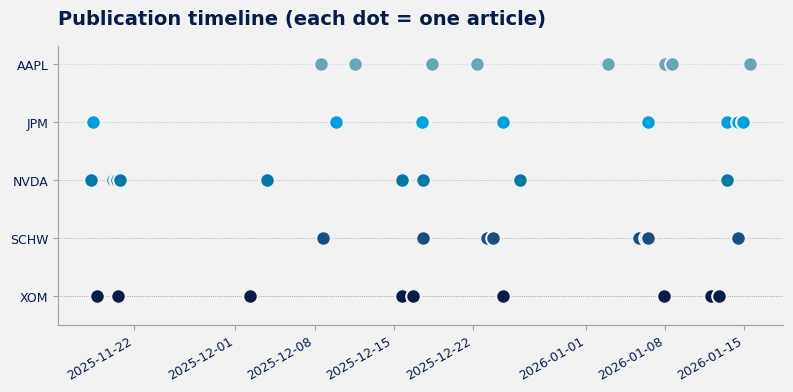

In [115]:
overview = articles.pivot_table(index="ticker", columns="source", values="article_id", aggfunc="count", fill_value=0)
overview["total"] = overview.sum(axis=1)
display(overview)

fig, ax = plt.subplots()
order = ["XOM", "SCHW", "NVDA", "JPM", "AAPL"]
for i, ticker in enumerate(order):
    color = SCHWAB_PALETTE[i]
    d = articles.loc[articles.ticker == ticker]
    ax.axhline(y=i, color=color, linestyle=":", linewidth=0.5, alpha=0.6, zorder=1)
    ax.scatter(d.published, [i] * len(d), s=110, color=color, edgecolor=SCHWAB_BACKGROUND, linewidth=1.5, zorder=3)
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.5, 4.3)
ax.set_title("Publication timeline (each dot = one article)", pad=16)
fig.autofmt_xdate()
save_fig("01_timeline")

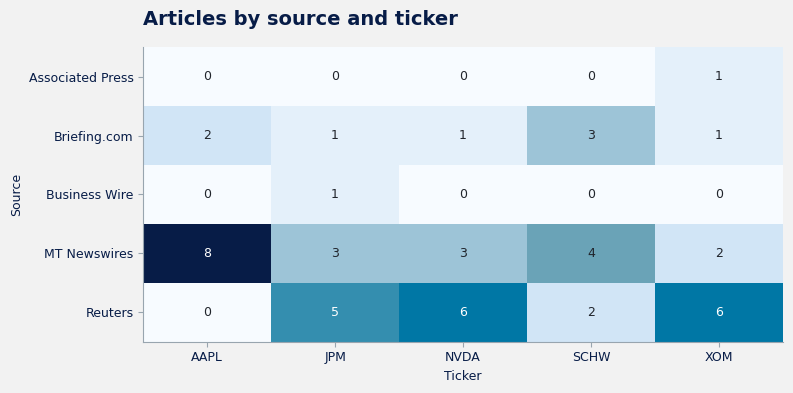

In [116]:
coverage = overview.drop(columns="total").T
cmap = LinearSegmentedColormap.from_list("schwab_blue", ["#F7FBFF", "#D2E6F7", "#6BA4B8", "#0079A7", "#071C47"])

fig, ax = plt.subplots()
ax.imshow(coverage, cmap=cmap, vmin=0, vmax=coverage.to_numpy().max(), aspect="auto")
ax.set_xticks(range(coverage.shape[1]), labels=coverage.columns)
ax.set_yticks(range(coverage.shape[0]), labels=coverage.index)
ax.set_title("Articles by source and ticker", pad=16)
ax.set_xlabel("Ticker"); ax.set_ylabel("Source")
for row in range(coverage.shape[0]):
    for col in range(coverage.shape[1]):
        count = int(coverage.iat[row, col])
        ax.text(col, row, str(count), ha="center", va="center", color="white" if count >= 5 else "#20242B")
save_fig("01b_source_by_ticker")

**Observations.**
* **Scope:** 49 articles, 5 tickers (≈10 each), 5 sources, Nov 18 2025 – Jan 15 2026.
* **Sources:** Reuters (long market wraps and exclusives) and MT Newswires (short wire items) supply 39 of the 49. Source mix differs by ticker: AAPL is almost all MT Newswires; NVDA and XOM are mostly Reuters.
* **Timing:** articles cluster around events (Nvidia earnings on Nov 19, bank earnings in mid-January).
* **Sample size:** with n = 49, every comparison later is paired by article and reported with confidence intervals.

### 1.3 Article length and how much information the body carries

In [117]:
BT_ORDER = ["title_only", "analyst_note", "brief", "full"]
display(articles.groupby("body_type")["informative_words"].describe().reindex(BT_ORDER).round(1))

,count,mean,std,min,25%,50%,75%,max
body_type,,,,,,,,
title_only,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
analyst_note,6.0,21.8,0.8,21.0,21.2,22.0,22.0,23.0
brief,16.0,91.9,29.6,52.0,67.5,89.0,117.2,145.0
full,22.0,417.0,176.3,175.0,277.5,352.0,551.2,752.0


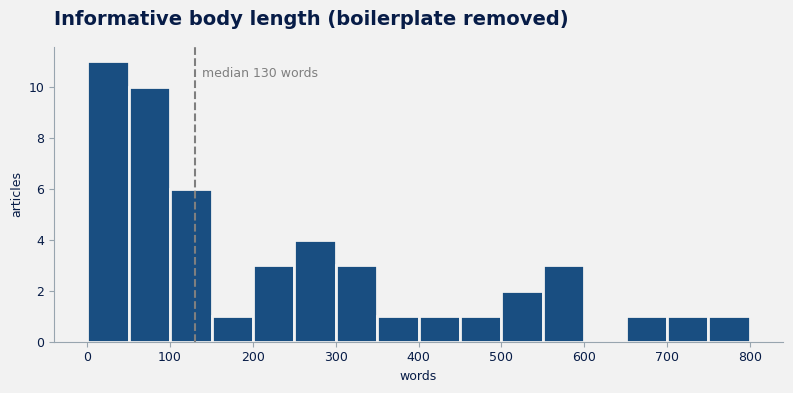

In [118]:
fig, ax = plt.subplots()
ax.hist(articles.informative_words, bins=np.arange(0, 801, 50), color=MID_NAVY, **BAR)
med = articles.informative_words.median()
ax.axvline(med, color=GRAY, lw=1.5, ls="--")
ax.text(med + 8, ax.get_ylim()[1] * 0.9, f"median {med:.0f} words", color=GRAY)
ax.set_title("Informative body length (boilerplate removed)", pad=16)
ax.set_xlabel("words"); ax.set_ylabel("articles")
save_fig("02_informative_body_length")

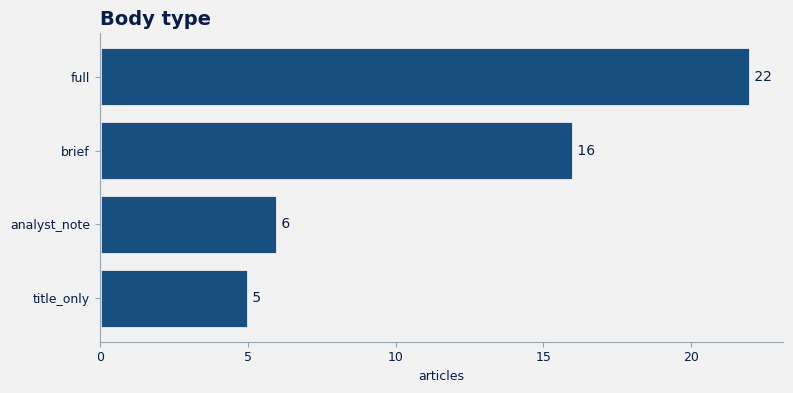

In [119]:
fig, ax = plt.subplots()
counts = articles.body_type.value_counts().sort_values(ascending=False)
bars = ax.barh(counts.index, counts.values, color=MID_NAVY, **BAR)
label_bars(ax, bars, horizontal=True)
ax.invert_yaxis()
ax.set_title("Body type")
ax.set_xlabel("articles")
save_fig("03_body_type")

**Observations.**
* **Articles are short.** The median is ≈130 informative words and the maximum ≈750. Every article fits in one call, so chunking is unnecessary; the design effort should go into *what* to extract.
* **11 of 49 (22%) have no informative body.**
  * 5 are *headline-only*.
  * 6 are *analyst notes*, where the news (e.g. *"KBW raises JPM PT to \$363 from \$354"*) is **only in the headline**, and the body is a generic FactSet consensus line (*mean target \$332.32*).
* **Three ways a summarizer can fail on these:**
  * It ignores the headline and loses the news.
  * It pads a one-line item and invents details.
  * It confuses the analyst's target with the consensus and reports a wrong number.

### 1.4 How numeric is the news?

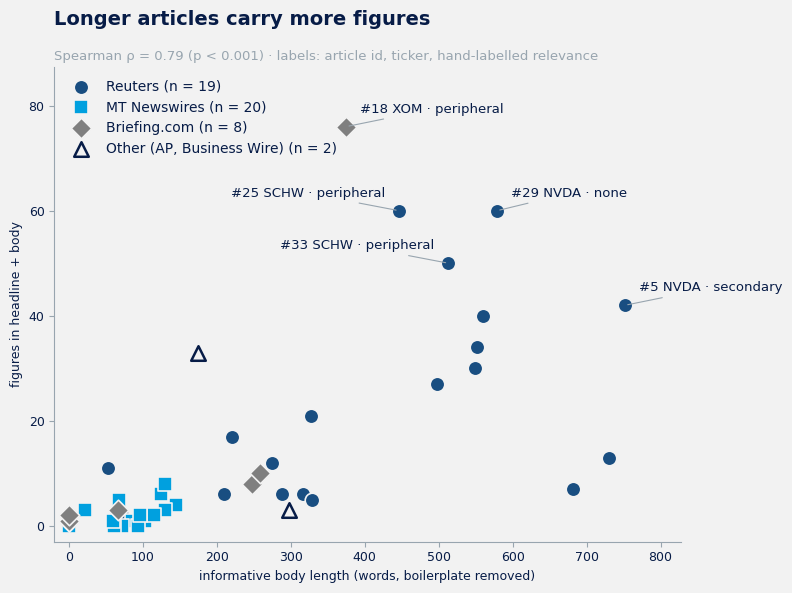

,articles,median_words,median_figures,figures_per_100_words
source,,,,
MT Newswires,20,70.0,3.0,3.6
Reuters,19,446.0,17.0,5.7
Briefing.com,8,33.0,2.5,10.8
Associated Press,1,297.0,3.0,1.0
Business Wire,1,175.0,33.0,18.9


In [120]:
# Figures ($, %, prices, counts) in headline + informative body. Numbers glued to a letter (Q4, H200) are identifiers.
_FIG_RE = re.compile(r"(?<![A-Za-z\d.])\$?(\d{1,3}(?:,\d{3})+|\d+)(\.\d+)?(?!\d)")
articles["n_figures"] = [len(_FIG_RE.findall(r.title + " " + informative_body(r.content))) for r in articles.itertuples()]

# Colour and marker per source; AP and Business Wire (one article each) share an "Other" style.
SOURCE_STYLE = {
    "Reuters":      dict(color=MID_NAVY, marker="o", label="Reuters"),
    "MT Newswires": dict(color=CYAN,     marker="s", label="MT Newswires"),
    "Briefing.com": dict(color=GRAY,     marker="D", label="Briefing.com"),
}
OTHER_STYLE = dict(color=SCHWAB_BACKGROUND, marker="^", label="Other (AP, Business Wire)")

fig, ax = plt.subplots(figsize=(8, 6))
for src, style in list(SOURCE_STYLE.items()) + [("__other__", OTHER_STYLE)]:
    d = articles[~articles.source.isin(SOURCE_STYLE)] if src == "__other__" else articles[articles.source == src]
    ax.scatter(d.informative_words, d.n_figures, s=110, marker=style["marker"], color=style["color"],
               edgecolor=NAVY if src == "__other__" else SCHWAB_BACKGROUND, linewidth=1.8 if src == "__other__" else 1.2,
               label=f"{style['label']} (n = {len(d)})", zorder=3)

# Label the five most figure-heavy articles with ticker and relevance; label goes left if crowded on the right.
top = articles.nlargest(5, "n_figures").sort_values("informative_words").reset_index(drop=True)
for _, r in top.iterrows():
    crowded = any((0 < o.informative_words - r.informative_words < 200) and abs(o.n_figures - r.n_figures) < 15
                  for _, o in top.iterrows())
    ax.annotate(f"#{r.article_id} {r.ticker} · {r.gold_relevance}", (r.informative_words, r.n_figures),
                xytext=(-10 if crowded else 10, 10), textcoords="offset points",
                ha="right" if crowded else "left", fontsize=9.5, color=NAVY,
                arrowprops=dict(arrowstyle="-", color=SCHWAB_SECONDARY_TEXT, lw=0.8))

rho, p = stats.spearmanr(articles.informative_words, articles.n_figures)
ax.set_xlabel("informative body length (words, boilerplate removed)")
ax.set_ylabel("figures in headline + body")
ax.set_xlim(-20, articles.informative_words.max() * 1.1)
ax.set_ylim(-3, articles.n_figures.max() * 1.15)
ax.legend(loc="upper left", fontsize=10)
ax.set_title("Longer articles carry more figures", pad=30)
ax.text(0, 1.015, f"Spearman ρ = {rho:.2f} (p < 0.001) · labels: article id, ticker, hand-labelled relevance",
        transform=ax.transAxes, fontsize=9.5, color=SCHWAB_SECONDARY_TEXT)
save_fig("04_numeric_density")

dens = articles.groupby("source").agg(articles=("n_figures", "size"), median_words=("informative_words", "median"),
                                      median_figures=("n_figures", "median"),
                                      figures=("n_figures", "sum"), words=("informative_words", "sum"))
dens["figures_per_100_words"] = (dens.figures / dens.words * 100).round(1)
display(dens.drop(columns=["figures", "words"]).sort_values("articles", ascending=False))

**Observations.**
* **Length and figure count are strongly related** (Spearman ρ = 0.79). A typical article carries about 6 figures per 100 words; Reuters market wraps carry 40–60 each.
* **The most figure-heavy articles are rarely about their ticker.**
  * Four of the five highest are sector briefings, research roundups and regional wraps that are *peripheral* or *unrelated* to their ticker (e.g. #18 XOM: 76 figures, one line on Exxon).
  * A summarizer has dozens of other companies' numbers to choose from there.
* **Short wires are dense but low-volume.** MT Newswires items have a median of 3 figures, but those figures *are* the news (a price target, a fine), so each must be exact.
* **Implication:** figures need a deterministic check (L1), and relevance triage matters most exactly where numbers are plentiful.

### 1.5 Is the article actually about its ticker?

gold_relevance,primary,secondary,peripheral,none,total
ticker,,,,,
AAPL,6,2,1,1,10
JPM,6,1,3,0,10
NVDA,5,2,2,1,10
SCHW,7,0,2,0,9
XOM,6,1,2,1,10


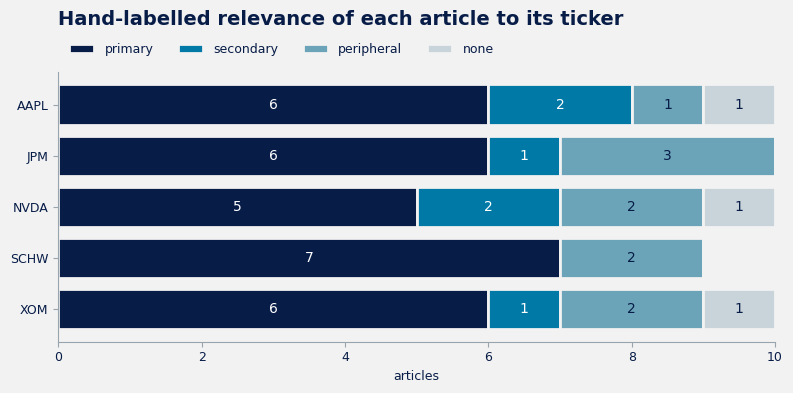

ticker named in body   False  True  All
ticker named in title                  
False                      3    13   16
True                       4    29   33
All                        7    42   49


,article_id,ticker,title,gold_relevance,gold_note
0,12,AAPL,--President Trump Says He Will Issue 'One Rule' Executive Order on AI This Week,none,Headline only: Trump to issue AI executive order; Apple not mentioned
1,15,AAPL,PAR Technology Launches Smart Passes Loyalty Tool for Restaurants,peripheral,PAR Technology product launch; Apple Wallet named as a channel
10,2,JPM,"EXCLUSIVE-Weinstein's Saba sells credit derivatives on Big Tech as AI risks grow, source says",peripheral,Saba sells Big Tech CDS; JPMorgan only named via the London Whale reference
17,45,JPM,US STOCKS-Wall Street futures decline ahead of big bank earnings,peripheral,US futures ahead of bank earnings; one sentence on JPM executives' card-cap warning
18,47,JPM,"US STOCKS-Wall Street ends lower, led by drop in Nasdaq, with tech, banks falling",peripheral,US market close; banks fall; one sentence on JPM executives' card-cap warning
20,1,NVDA,Japan's Nikkei falls 3% on tech selloff,peripheral,Nikkei market wrap; Nvidia only mentioned as upcoming earnings catalyst
27,21,NVDA,US STOCKS-Wall St inches up as investors eye policy outlook; Oracle slides,peripheral,US market wrap on Oracle funding worries; Nvidia -1.8% in one sentence
28,29,NVDA,"EMERGING MARKETS-Asian equities set for strong weekly gains; Taiwan, S.Korea lead tech-driven surge",none,Asian EM wrap on AI-driven tech rally; Nvidia never mentioned
32,25,SCHW,"U.S. RESEARCH ROUNDUP-APi Group, Elf Beauty, Tesla",peripheral,Research roundup; one line: Morgan Stanley raises SCHW target to $148
35,33,SCHW,"U.S. RESEARCH ROUNDUP-Brunswick, Parker-Hannifin, XPLR Infrastructure",peripheral,Research roundup; one line: Jefferies raises SCHW target to $121


In [121]:
rel = pd.crosstab(articles.ticker, articles.gold_relevance).reindex(columns=REL_ORDER, fill_value=0)
display(rel.assign(total=rel.sum(axis=1)))

fig, ax = plt.subplots()
left = np.zeros(len(rel))
for lvl in REL_ORDER:
    bars = ax.barh(rel.index, rel[lvl], left=left, color=RELEVANCE_COLORS[lvl], label=lvl, **BAR)
    for b, v in zip(bars, rel[lvl]):
        if v > 0:
            ax.text(b.get_x() + b.get_width() / 2, b.get_y() + b.get_height() / 2, str(v), ha="center", va="center",
                    color="white" if lvl in ("primary", "secondary") else NAVY, fontsize=10)
    left += rel[lvl].values
ax.invert_yaxis()
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.02))
ax.set_title("Hand-labelled relevance of each article to its ticker", pad=34)
ax.set_xlabel("articles")
save_fig("05_relevance_by_ticker")

print(pd.crosstab(articles.ticker_in_title, articles.ticker_in_body, margins=True,
                  rownames=["ticker named in title"], colnames=["ticker named in body"]))
display(articles[articles.gold_relevance.isin(["none", "peripheral"])][["article_id", "ticker", "title", "gold_relevance", "gold_note"]])

**Observations.**
* **Only 30 of 49 (61%) are primarily about their ticker.**
* **13 (27%) are peripheral or unrelated.**
  * Market wraps, such as the Nikkei selloff filed under NVDA.
  * Research roundups where the ticker is one line of 30.
  * Three articles that never mention the ticker at all.
* **The ticker isn't named in the headline in 16 cases.**
* **The key risk** is therefore not a garbled summary but a *plausible, confident link to the ticker that the article does not make* (e.g. "strong Asian AI demand bodes well for Nvidia").

### 1.6 Topics / event types
Keyword tagging on the headline and lead; the first rule that matches wins. Wire slugs such as `US STOCKS-` are matched case-sensitively. Otherwise ordinary words ("AI stocks have sold off", "ex-markets") would mis-tag articles as market wraps.

ticker,AAPL,JPM,NVDA,SCHW,XOM,total
event_type_eda,,,,,,
market wrap / sector,2,3,6,0,1,12
corporate / product / other,3,3,1,3,1,11
analyst action,0,2,0,6,0,8
M&A / deals / assets,1,0,1,0,6,8
regulatory / legal / policy,4,0,1,0,1,6
earnings / guidance,0,2,1,0,1,4


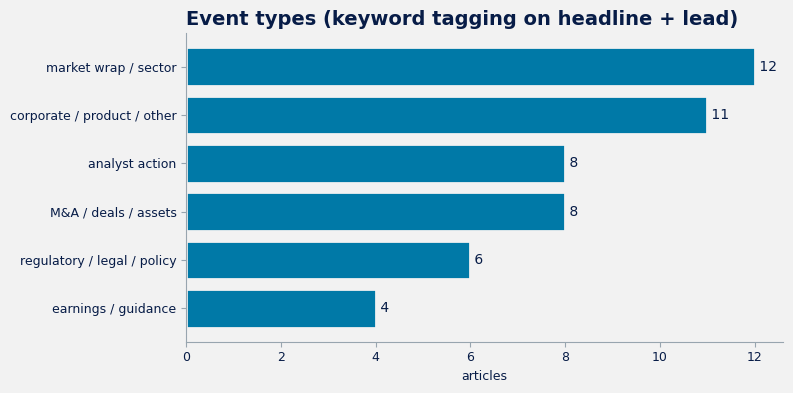

In [122]:
EVENT_RULES = [  # (label, pattern, case_sensitive)
    ("analyst action", r"\bAdjusts (PT|Price Target)\b|\btarget price\b|\bRESEARCH ROUNDUP\b", False),
    ("market wrap / sector", r"\b(?:US STOCKS|GLOBAL MARKETS|EMERGING MARKETS)-|\bNikkei\b|\bSector (?:Update|Briefing)\b|\b52-week\b|\bgapped\b", True),
    ("earnings / guidance", r"\bearnings\b|\bprofits?\b|\boutlook\b|\bquarter(?:ly)?\b|\b(?:quarterly|financial) results\b|\brevenue\b|\bsales\b|\bnet interest income\b", False),
    ("M&A / deals / assets", r"\bacquir\w*|\bLukoil\b|\bstakes?\b|\bbids?\b|\bDeals of the day\b|\bissuer\b", False),
    ("regulatory / legal / policy", r"\bantitrust\b|\bfined?\b|\bregulat\w*|\bexport controls?\b|\bcomply\b|\bcompetition\b|\bexecutive order\b|\bVenezuela\b|\bdeadline\b", False),
    ("corporate / product / other", r".", False),
]


def tag_event(title: str, content: str) -> tuple[str, str]:
    """(event label, matched text) for the headline + first 300 characters."""
    text = title + " " + content[:300]
    for label, pattern, case_sensitive in EVENT_RULES:
        m = re.search(pattern, text, 0 if case_sensitive else re.I)
        if m:
            return label, m.group(0)


articles[["event_type_eda", "event_trigger"]] = [tag_event(r.title, r.content) for r in articles.itertuples()]
ev = pd.crosstab(articles.event_type_eda, articles.ticker)
ev = ev.assign(total=ev.sum(axis=1)).sort_values("total")
display(ev.iloc[::-1])

fig, ax = plt.subplots()
bars = ax.barh(ev.index, ev.total, color=TEAL, **BAR)
label_bars(ax, bars, horizontal=True)
ax.set_title("Event types (keyword tagging on headline + lead)")
ax.set_xlabel("articles")
save_fig("06_event_types")

**Observations.**
* **The mix differs by ticker:**
  * SCHW: analyst price-target notes and its own trading-activity index.
  * XOM: the Lukoil asset saga and policy news.
  * NVDA: its earnings week and market wraps.
  * AAPL: regulation and antitrust.
  * JPM: results, guidance and market wraps.
* **The same event can be filed under different tickers.** The Apple Card moving to Chase appears under both AAPL and JPM, so a summary must be written *from the ticker's perspective*.

### 1.7 Data quality

In [123]:
pd.DataFrame({
    "issue": ["stray '?' artifacts (Reuters)", "headline-only (empty body)", "analyst note: news only in headline",
              "wire boilerplate (dateline / price trailer / disclaimer)", "missing spaces (e.g. 'fortheir')"],
    "articles": [int((articles.artifacts_fixed > 0).sum()), int((articles.body_type == "title_only").sum()),
                 int((articles.body_type == "analyst_note").sum()),
                 int((articles.body_words - articles.informative_words > 3).sum()),
                 int(articles.content.str.contains(r"fortheir|arally|atwo", regex=True).sum())],
    "handling": ["removed in cleaning", "headline passed explicitly; model told the body is missing",
                 "headline passed explicitly; B told to prefer it over boilerplate",
                 "kept in input, excluded from length stats", "left as is (LLMs read through it)"]})

,issue,articles,handling
0,stray '?' artifacts (Reuters),9,removed in cleaning
1,headline-only (empty body),5,headline passed explicitly; model told the body is missing
2,analyst note: news only in headline,6,headline passed explicitly; B told to prefer it over boilerplate
3,wire boilerplate (dateline / price trailer / disclaimer),20,"kept in input, excluded from length stats"
4,missing spaces (e.g. 'fortheir'),1,left as is (LLMs read through it)


### 1.8 What the EDA implies for the design
| Finding | Implication |
|:---|:---|
| Articles are short; all fit in context | No chunking. Invest in *what* to extract. |
| 27% peripheral or unrelated to the ticker | Summaries must be **ticker-conditioned** and able to say *"not really about this stock"*. Evaluation needs a **ticker-focus** criterion and an **overstated-link** check. |
| 22% have no informative body | Use the headline explicitly; prefer honest "limited information" to padding. Evaluate **thin inputs** as their own slice. |
| News is numeric, and figure-heavy articles are often off-ticker | Figures must be preserved exactly → a deterministic **numeric check** (LLM judges are weak at exact figures). |
| Small n (49) | Paired comparisons with bootstrap CIs, per-slice results, qualitative error analysis. |

## 2. Methodology Design

**What a good summary is for.** An analyst covering a stock reads the summary *instead of* the article to decide whether the item matters. So a good summary:
1. States nothing the article doesn't support. A wrong or untraceable fact is worse than a missing one.
2. Is honest about how relevant the article is to the ticker.
3. Keeps the event, the key figures and their attribution.
4. Is fast to scan.

**Design decisions**

| Decision | Choice | Alternatives considered | Why |
|:---|:---|:---|:---|
| Input | Headline + cleaned body (boilerplate kept) | Body only | 11/49 articles carry the news only in the headline |
| Context | Whole article in one call | Chunking / map-reduce | Longest article is ~750 words |
| Generator | `claude-sonnet-5` for both approaches | Frontier model; open fine-tuned summarizers (PEGASUS-financial, FinLlama3-sum) | A mid-size model is enough for short inputs. Open summarizers are trained on generic one-sentence references and can't be told which ticker matters (§5.5) |
| Approach A | Ticker-aware prose, ≤100 words | Generic "summarize this" | A realistic, strong baseline: B's gains can't come merely from knowing the ticker |
| Approach B | JSON: relevance, event type, ≤50-word summary, ≤3 key facts, sentiment, information quality; explicit grounding rules | Few-shot examples, chain-of-thought, multi-model voting | Each field answers an EDA finding. The brief asks for 2 meaningful variations, not prompt tuning |
| Output format | Structured outputs (JSON schema) for B | Prompt-only JSON | In the first run, 2/49 prompt-only replies were invalid JSON (unescaped quotes in a quotation) |
| Held constant | Model, input text, evaluation | — | Isolates the effect of the task specification |

**The two approaches**

| | **A — Simple (baseline)** | **B — Structured, grounded, triaged** |
|:---|:---|:---|
| Knows the target ticker | yes | yes |
| Output | One prose paragraph ≤100 words | Relevance, event type, ≤50-word summary, ≤3 key facts, sentiment + rationale, information quality |
| Grounding rules | None (implicit) | Only article facts; keep figures verbatim; attribute rumours and analyst views; use the headline when the body is boilerplate |
| Relevance handling | None | Explicit 4-level triage; must say plainly when the ticker is peripheral or absent; no invented links |

The evaluators see B as a short analyst-facing text: a relevance/sentiment header, the summary and the key facts. The judge therefore always compares text with text. §4.11 checks whether B's header alone explains its advantage.

In [124]:
SIMPLE_SYSTEM = "You are a financial analyst."
SIMPLE_PROMPT = '''Summarize the following news article for an investor who follows {company} ({ticker}).
Write a single paragraph of at most 100 words.

{article}'''

STRUCTURED_SYSTEM = (
    "You are an equity research assistant at a brokerage. Analysts use your summaries to decide "
    "quickly whether a news item matters for a specific stock. Accuracy matters more than completeness: "
    "never state anything the article does not support."
)
STRUCTURED_PROMPT = '''Target stock: {company} ({ticker})

<article>
{article}
</article>

Instructions:
1. Classify how relevant the article is to {ticker}:
   - "primary": {company} is the main subject.
   - "secondary": {company} is one of several subjects, or a key driver of the story.
   - "peripheral": {company} is only mentioned in passing.
   - "none": {company} is not mentioned; any link would be your own inference.
2. Use only information stated in the article (headline + body). Do not add background knowledge,
   prices or context that is not in the text. If the body is missing or is generic boilerplate,
   rely on the headline and set "information_quality" to "limited".
3. Keep figures (prices, %, $ amounts, dates) exactly as written. Attribute analyst opinions,
   rumours and "sources say" reports as such.
4. Write for an investor in {ticker}: the event, the key numbers, and why it could matter for the stock.
   If relevance is "peripheral" or "none", say so plainly and cover only what concerns {ticker}
   (or, if nothing does, the market context in one sentence). Do not invent a connection.

Return only a JSON object with exactly these keys:
{{
  "relevance": "primary" | "secondary" | "peripheral" | "none",
  "event_type": "earnings_guidance" | "analyst_action" | "m_and_a" | "regulatory_legal" | "product_business" | "macro_market" | "management_corporate" | "other",
  "summary": "<= 50 words, focused on {ticker}",
  "key_facts": ["<= 3 short facts, each <= 15 words, keep figures"],
  "sentiment_for_ticker": "positive" | "negative" | "neutral" | "mixed",
  "sentiment_rationale": "<= 20 words",
  "information_quality": "full" | "limited"
}}'''


class StructuredSummary(BaseModel):
    """JSON schema enforced on Approach B's output."""
    relevance: Literal["primary", "secondary", "peripheral", "none"]
    event_type: Literal["earnings_guidance", "analyst_action", "m_and_a", "regulatory_legal",
                        "product_business", "macro_market", "management_corporate", "other"]
    summary: str
    key_facts: list[str]
    sentiment_for_ticker: Literal["positive", "negative", "neutral", "mixed"]
    sentiment_rationale: str
    information_quality: Literal["full", "limited"]

In [125]:
VALID_RELEVANCE = set(REL_ORDER)
ART = articles.set_index(["article_id", "ticker"], drop=False)   # lookup by (article, ticker)


def render_structured(ticker: str, p: dict) -> str:
    """Analyst-facing text view of a B output: header, summary, up to 3 key facts."""
    facts = [str(f).strip() for f in (p.get("key_facts") or []) if str(f).strip()][:3]
    lines = [f"[{ticker} relevance: {p.get('relevance', '?')} | sentiment: {p.get('sentiment_for_ticker', '?')}]",
             str(p.get("summary", "")).strip()]
    if facts:
        lines += ["Key facts:"] + [f"- {f}" for f in facts]
    return "\n".join(lines)


def summarize_one(row: pd.Series, approach: str) -> dict:
    """Summarize one article with approach A or B; returns one result row."""
    fmt = dict(company=row.company, ticker=row.ticker, article=row.model_input)
    out = {"article_id": row.article_id, "ticker": row.ticker, "approach": approach, "raw": None, "text": None, "parse_ok": None}
    if approach == "A_simple":
        raw = GEN.complete(SIMPLE_PROMPT.format(**fmt), SIMPLE_SYSTEM)
        out.update(raw=raw, text=raw.strip(), parse_ok=True)
        return out
    raw = GEN.complete(STRUCTURED_PROMPT.format(**fmt), STRUCTURED_SYSTEM, schema=StructuredSummary)
    out["raw"] = raw
    try:
        p = parse_json(raw)
        rel = str(p.get("relevance", "")).lower().strip()
        out.update(parse_ok=rel in VALID_RELEVANCE and bool(p.get("summary")), text=render_structured(row.ticker, p),
                   pred_relevance=rel, event_type=p.get("event_type"), sentiment=p.get("sentiment_for_ticker"),
                   information_quality=p.get("information_quality"), summary_field=p.get("summary"))
    except (ValueError, TypeError) as exc:            # invalid JSON: keep the raw text and flag it
        out.update(parse_ok=False, text=raw.strip(), error=f"parse: {exc}")
    return out


def run_approach(approach: str) -> pd.DataFrame:
    """Summarize all articles with one approach, in parallel."""
    return pd.DataFrame(parallel_map(lambda r: summarize_one(r, approach), [r for _, r in articles.iterrows()], approach))

## 3. Evaluation Framework

There is no reference summary, and "good" has several dimensions, so no single metric suffices. ROUGE and BERTScore need references, and they reward matching a reference's style rather than accuracy. The framework therefore has five layers, from the cheapest and most objective to the most flexible. **The flexible layer (the LLM judge) is itself tested before its scores are trusted.**

| Layer | What it measures | Why | Blind spot |
|:---|:---|:---|:---|
| **L1 Deterministic checks** | Numeric precision: every figure in the summary must match a figure in the article (rounding and units allowed). Plus reversed old/new pairs, length, valid output | Exact, free, reproducible. Numbers are where LLM judges are weakest | Blind to omissions, relevance and non-numeric errors |
| **L2 Human labels** | B's relevance label vs the hand labels | The one quality that is cheap to label objectively | Relevance only |
| **L3 LLM judge: rubric** | The judge first **lists each unsupported claim with its type and severity**, and the missing key facts, *then* scores 1–5 on faithfulness, ticker focus, coverage and conciseness. Also flags overstated ticker links | Covers meaning that rules can't check; the claim list makes each score auditable and countable | Judge biases: length, self-preference, position, leniency |
| **L4 LLM judge: pairwise** | Which summary serves the analyst better, asked **in both orders**. A verdict counts only if it survives the swap | Preference judgments are more reliable than absolute scores; the swap measures position bias | Relative only |
| **L5 Evaluator validation** | (a) **Repeat-run noise:** judge identical text twice. (b) **Injected errors:** known errors in clean summaries; is the specific error named? (c) **Independent review** of 24 blinded summaries | Shows which errors each evaluator can see, and how big a difference must be to be real | Synthetic errors are cleaner than natural ones |

**Claim types** recorded by the judge:
* `outside_fact`: a fact, number or date not in the article.
* `wrong_detail`: contradicts the article (number, direction, entity, date).
* `unattributed`: a sourced or rumoured report stated as fact.
* `speculation`: an opinion, implication or forecast the article doesn't make, including an invented link to the ticker.

Each claim is also marked `material` (could change an investment view) or `minor`.

**Controls for judge bias:**
* **Stronger judge:** a different, stronger model than the generator.
* **Anchored rubric:** each score level is described, with an explicit "don't reward length".
* **Blind:** approach identities are hidden.
* **Order swap:** pairwise questions are asked in both orders.
* **Structured output:** the judge's reply is schema-constrained, with a 4,000-token budget so long claim lists aren't cut off.

**Primary metrics, fixed before running:** faithfulness (and the unsupported-claim count), and ticker focus. Coverage and conciseness are secondary.

**Hypotheses, written before running:**
* **H1:** On *peripheral/unrelated* articles, B has higher ticker focus and fewer overstated links.
* **H2:** On *thin inputs* (headline-only, analyst notes), B has fewer unsupported claims.
* **H3:** On *substantive, relevant* articles the two are close, and A may win on coverage because B's summary is shorter.

**Grounding in prior work**
* **Scoring:** enumerate claims before scoring. This combines rubric scoring (G-Eval, Liu et al., 2023), atomic-fact checking (FActScore, Min et al., 2023) and checklist-style judging, which improves agreement over holistic 1–5 scores (CheckEval, Lee et al., EMNLP 2025).
* **Judge biases:** position bias (Zheng et al., 2023, *MT-Bench*) and self-preference (Panickssery et al., NeurIPS 2024).
* **Hallucination in abstractive summarization:** Maynez et al., 2020.

### 3.1 L1: deterministic checks
Figures are converted to full values before comparison ($4.6 billion = $4,600 million), and percentages only match percentages. Number words in the source ("three") count as figures.

A figure that isn't found is classified as one of:
* *derivable* by simple arithmetic on article figures (e.g. $1,000 + $1,000);
* a *year* not in the article;
* *not in the article*.

The wire trailer `Percent Change: -0.31` is read as a percentage. In the first run it caused false alarms when summaries correctly wrote "down 0.31%".

In [126]:
# Simple figure pattern, used by the number_swap perturbation (§3.3).
_NUM = re.compile(r"(?<![A-Za-z\d.])\$?(\d{1,3}(?:,\d{3})+|\d+)(\.\d+)?(?!\d)")

REL_TOL = 0.02   # a figure may differ by rounding of its last digit AND by at most 2%
_SCALES = {"thousand": 1e3, "k": 1e3, "million": 1e6, "mln": 1e6, "mn": 1e6, "m": 1e6,
           "billion": 1e9, "bn": 1e9, "b": 1e9, "trillion": 1e12, "tn": 1e12, "t": 1e12}
# Figure = optional $, digits, decimals, scale word/letter, percent. Skips identifiers (Q4, H200) and ordinals (4th).
_NUM2 = re.compile(
    r"(?<![A-Za-z\d.])(?P<cur>\$)?\s?(?P<int>\d{1,3}(?:,\d{3})+|\d+)(?P<dec>\.\d+)?(?!\d|(?:st|nd|rd|th)\b)"
    r"(?:\s?(?P<scale_word>thousand|million|billion|trillion|mln|mn|bn|tn)\b|(?P<scale_letter>[kKmMbBtT])\b)?"
    r"(?P<pct>\s?(?:%|percent\b|pct\b))?",
    re.I,
)
_WORD_NUMS = {w: i for i, w in enumerate(
    "zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen "
    "fifteen sixteen seventeen eighteen nineteen twenty".split())}
_WORD_NUMS.update({"thirty": 30, "forty": 40, "fifty": 50, "sixty": 60, "seventy": 70,
                   "eighty": 80, "ninety": 90, "hundred": 100, "dozen": 12})
_WORD_NUM_RE = re.compile(r"\b(" + "|".join(_WORD_NUMS) + r")\b", re.I)
_PCT_CHANGE = re.compile(r"(Percent Change:\s*[-+]?\d[\d.,]*)")
_FIG = r"\$?\d[\d,]*(?:\.\d+)?%?"
_TO_FROM = re.compile(rf"\bto\s+({_FIG})\s+from\s+({_FIG})", re.I)   # (new, old)
_FROM_TO = re.compile(rf"\bfrom\s+({_FIG})\s+to\s+({_FIG})", re.I)   # (old, new)
_B_HEADER = re.compile(r"^\[[A-Z.]+ relevance: [^\]]*\]\s*$|^Key facts:\s*$", re.M)


@dataclass(frozen=True)
class Figure:
    value: float      # full value: "$4.6 billion" -> 4.6e9
    half_unit: float  # half of the last digit shown, at that scale
    is_pct: bool
    raw: str


def extract_figures(text: str, spelled_out: bool = False) -> list[Figure]:
    """All figures in text as full values; spelled_out=True also reads number words. Signs are ignored."""
    figs = []
    for m in _NUM2.finditer(text):
        dec = m.group("dec") or ""
        scale_key = (m.group("scale_word") or m.group("scale_letter") or "").lower()
        if m.group("scale_letter") and not m.group("cur"):   # a bare letter is a scale only after $
            scale_key = ""
        scale = _SCALES.get(scale_key, 1.0)
        value = float(m.group("int").replace(",", "") + dec) * scale
        figs.append(Figure(value, 0.5 * 10 ** -max(len(dec) - 1, 0) * scale, bool(m.group("pct")), m.group(0).strip()))
    if spelled_out:
        figs += [Figure(float(_WORD_NUMS[m.group(1).lower()]), 0.5, False, m.group(0)) for m in _WORD_NUM_RE.finditer(text)]
    return figs


def _source_figures(source: str) -> list[Figure]:
    """Source figures, reading 'Percent Change: x' as a percentage."""
    return extract_figures(_PCT_CHANGE.sub(r"\1%", source), spelled_out=True)


def _same(s: Figure, x: Figure) -> bool:
    """Does summary figure s faithfully render source figure x?"""
    diff = abs(x.value - s.value)
    return s.is_pct == x.is_pct and diff <= s.half_unit * (1 + 1e-9) and diff <= REL_TOL * max(abs(x.value), 1e-12)


def unsupported_figures(summary: str, source: str) -> list[str]:
    """Figures in the summary that no source figure supports (as written)."""
    src = _source_figures(source)
    return [s.raw for s in extract_figures(summary) if not any(_same(s, x) for x in src)]


def classify_unsupported(fig: str, source: str) -> str:
    """'derivable' (sum/difference/product/ratio/% change of two article figures), 'year not in article', or 'not in article'."""
    s = extract_figures(fig)[0]
    if re.fullmatch(r"(19|20)\d\d", s.raw):   # bare 4-digit year (not "$2,000")
        return "year not in article"
    vals = [x.value for x in _source_figures(source)]
    tol = max(s.half_unit, REL_TOL * abs(s.value))
    for i, a in enumerate(vals):
        for b in vals[i:]:
            cands = [a + b, abs(a - b), a * b] + ([a / b, (a / b - 1) * 100] if b else []) + ([b / a, (b / a - 1) * 100] if a else [])
            if any(abs(abs(c) - s.value) <= tol for c in cands):
                return "derivable"
    return "not in article"


def _pairs(text: str) -> set[tuple[float, float]]:
    """(old, new) value pairs from 'to X from Y' / 'from Y to X'."""
    def v(t):
        f = extract_figures(t)
        return f[0].value if f else None
    out = {(v(old), v(new)) for new, old in _TO_FROM.findall(text)} | {(v(old), v(new)) for old, new in _FROM_TO.findall(text)}
    return {p for p in out if None not in p and p[0] != p[1]}


def swapped_pairs(summary: str, source: str) -> list[tuple[float, float]]:
    """Old/new pairs the summary states in reverse (e.g. 'cut to $354 from $363' vs 'raised to $363 from $354')."""
    src = _pairs(source)
    return [p for p in _pairs(summary) if (p[1], p[0]) in src and p not in src]


def summary_body(text: str) -> str:
    """B's text without its header and 'Key facts:' label, for like-for-like metrics with A."""
    return _B_HEADER.sub("", text).strip()


def heuristic_metrics(summary: str, row: pd.Series) -> dict:
    body = summary_body(summary)
    figs, bad = extract_figures(body), unsupported_figures(body, row.model_input)
    return {"words": len(body.split()), "n_numbers": len(figs), "n_unsupported_numbers": len(bad),
            "unsupported_numbers": bad, "numeric_precision": (1 - len(bad) / len(figs)) if figs else np.nan,
            "n_swapped_pairs": len(swapped_pairs(body, row.model_input)),
            "mentions_ticker": mentions_ticker(body, row.ticker)}


def add_heuristics(df: pd.DataFrame) -> pd.DataFrame:
    """Append L1 metric columns to a summaries frame."""
    rows = [heuristic_metrics(s.text, ART.loc[(s.article_id, s.ticker)]) if isinstance(s.text, str) else {}
            for _, s in df.iterrows()]
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(rows)], axis=1)

### 3.2 L3 / L4: the LLM judge

In [127]:
JUDGE_SYSTEM = ("You are a meticulous senior equity research editor. You audit news summaries written for analysts. "
                "You are strict about factual accuracy and you do not reward length.")

JUDGE_POINTWISE_PROMPT = '''An analyst covering {company} ({ticker}) will read the SUMMARY instead of the ARTICLE.
Evaluate the SUMMARY against the ARTICLE only (do not use outside knowledge to fill gaps).

<article>
{article}
</article>

<summary>
{summary}
</summary>

Step 1 - Claim check. List every claim in the summary that is NOT supported by the article. For each give:
  type: "outside_fact" (a fact, number or date not in the article), "wrong_detail" (contradicts the article:
        number, direction, entity, date), "unattributed" (a sourced or rumoured report stated as fact),
        "speculation" (an opinion, implication or forecast the article does not make, incl. links to {ticker})
  severity: "material" (could change an investment view) or "minor" (no investment impact)
Step 2 - Omissions. List the most important investment-relevant facts about {ticker} in the article that
the summary misses (at most 3).
Step 3 - Score each criterion from 1 to 5:

faithfulness
  5 every claim supported | 4 minor imprecision with no investment impact | 3 one unsupported or distorted claim
  2 several unsupported claims, or one material error (number, direction, company) | 1 largely unsupported
ticker_focus  (does it tell a {ticker} analyst what matters, and represent how central {ticker} really is?)
  5 centred on what matters for {ticker}, and says so plainly if {ticker} is peripheral or absent
  3 a generic article summary; the {ticker} angle is implicit or buried
  1 ignores {ticker}, or implies the article is about / important for {ticker} when it is not
coverage  (key investment-relevant facts: the event, key figures, attribution)
  5 all key facts | 3 misses some important facts | 1 misses the main point
conciseness
  5 no filler, easy to scan | 3 some redundancy or filler | 1 verbose or hard to parse

Return only JSON:
{{
  "unsupported_claims": [{{"claim": "...", "type": "outside_fact" | "wrong_detail" | "unattributed" | "speculation", "severity": "material" | "minor"}}],
  "missing_key_facts": ["..."],
  "overstates_ticker_link": true | false,
  "faithfulness": 1-5,
  "ticker_focus": 1-5,
  "coverage": 1-5,
  "conciseness": 1-5
}}'''

JUDGE_PAIRWISE_PROMPT = '''An analyst covering {company} ({ticker}) will read ONE of two summaries instead of the article.
Which summary serves that analyst better? Judge against the ARTICLE only.
Priorities, in order: (1) factual accuracy - any unsupported claim is a serious defect;
(2) usefulness for a {ticker} analyst, including representing honestly how relevant the article is to {ticker};
(3) concision. Ignore formatting differences and do not prefer a summary for being longer.

<article>
{article}
</article>

<summary_1>
{summary_1}
</summary_1>

<summary_2>
{summary_2}
</summary_2>

Return only JSON: {{"reason": "<= 40 words", "winner": "1" | "2" | "tie"}}'''

CRITERIA = ["faithfulness", "ticker_focus", "coverage", "conciseness"]
CLAIM_TYPES = ["outside_fact", "wrong_detail", "unattributed", "speculation"]


class Claim(BaseModel):
    claim: str
    type: Literal["outside_fact", "wrong_detail", "unattributed", "speculation"]
    severity: Literal["material", "minor"]


class PointwiseJudgment(BaseModel):
    """Field order makes the judge list evidence before it scores."""
    unsupported_claims: list[Claim]
    missing_key_facts: list[str]
    overstates_ticker_link: bool
    faithfulness: Literal[1, 2, 3, 4, 5]
    ticker_focus: Literal[1, 2, 3, 4, 5]
    coverage: Literal[1, 2, 3, 4, 5]
    conciseness: Literal[1, 2, 3, 4, 5]


class PairwiseJudgment(BaseModel):
    reason: str
    winner: Literal["1", "2", "tie"]


def judge_pointwise_one(row: pd.Series, summary: str, replicate: int = 0) -> dict:
    """Rubric judgment of one summary against its article."""
    out = {c: None for c in CRITERIA} | {"unsupported_claims": None, "missing_key_facts": None,
                                         "overstates_ticker_link": None, "judge_error": None}
    prompt = JUDGE_POINTWISE_PROMPT.format(company=row.company, ticker=row.ticker, article=row.model_input, summary=summary)
    try:
        j = parse_json(JUDGE.complete(prompt, JUDGE_SYSTEM, schema=PointwiseJudgment, replicate=replicate))
        for c in CRITERIA:
            v = j.get(c)
            out[c] = int(v) if isinstance(v, (int, float)) or (isinstance(v, str) and v.isdigit()) else None
        claims = j.get("unsupported_claims") or []
        out["unsupported_claims"] = [c if isinstance(c, dict) else {"claim": str(c), "type": "unknown", "severity": "unknown"}
                                     for c in claims]
        out["missing_key_facts"] = list(j.get("missing_key_facts") or [])
        out["overstates_ticker_link"] = j.get("overstates_ticker_link") is True
    except (ValueError, TypeError) as exc:
        out["judge_error"] = f"parse: {exc}"
    claims = out["unsupported_claims"]
    out["n_unsupported_claims"] = len(claims) if claims is not None else None
    out["n_material_claims"] = sum(c.get("severity") == "material" for c in claims) if claims is not None else None
    return out


def judge_pointwise(df: pd.DataFrame, replicate: int = 0, desc: str = "pointwise judge") -> pd.DataFrame:
    """Judge every summary in df['text']; returns df with judgment columns appended."""
    jobs = [(ART.loc[(s.article_id, s.ticker)], s.text) for _, s in df.iterrows()]
    res = parallel_map(lambda j: judge_pointwise_one(*j, replicate=replicate) if isinstance(j[1], str) else {}, jobs, desc)
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(res)], axis=1)


def _pairwise_call(row, s1, s2):
    prompt = JUDGE_PAIRWISE_PROMPT.format(company=row.company, ticker=row.ticker, article=row.model_input, summary_1=s1, summary_2=s2)
    try:
        w = str(parse_json(JUDGE.complete(prompt, JUDGE_SYSTEM, schema=PairwiseJudgment)).get("winner", "")).strip().lower()
        return w if w in {"1", "2", "tie"} else None
    except (ValueError, TypeError):
        return None


def judge_pairwise(a: pd.DataFrame, b: pd.DataFrame) -> pd.DataFrame:
    """A vs B per article, asked in both orders; a verdict that flips with order is 'inconsistent'."""
    m = a[["article_id", "ticker", "text"]].merge(b[["article_id", "ticker", "text"]], on=["article_id", "ticker"], suffixes=("_A", "_B"))

    def one(x):
        row = ART.loc[(x.article_id, x.ticker)]
        v1, v2 = _pairwise_call(row, x.text_A, x.text_B), _pairwise_call(row, x.text_B, x.text_A)
        w1 = {"1": "A", "2": "B", "tie": "tie"}.get(v1)
        w2 = {"1": "B", "2": "A", "tie": "tie"}.get(v2)
        verdict = None if (w1 is None or w2 is None) else (w1 if w1 == w2 else "inconsistent")
        return {"article_id": x.article_id, "ticker": x.ticker, "A_first": w1, "B_first": w2, "verdict": verdict,
                "first_shown_won_1": v1 == "1", "first_shown_won_2": v2 == "1"}
    return pd.DataFrame(parallel_map(one, [x for _, x in m.iterrows()], "pairwise judge"))

### 3.3 L5: validating the evaluators
* **Repeat-run noise.** Judge 20 summaries a second time. The rate of "phantom" score drops is the noise floor that any detection rate must beat.
* **Injected errors.** Known errors are inserted into B summaries that the judge rated clean (faithfulness ≥ 4), editing only the summary text, not the header. An error counts as **caught by name** only when the judge's claim list names the injected item (the new number, the competitor, "buyback", the flipped word). The looser "score dropped or claim count rose" is reported alongside. A meaning-preserving control edit measures false alarms.
* **Independent review.** 24 blinded summaries (both approaches for 12 articles) rated on the same rubric; compare with the judge on identical text.

In [128]:
COMPETITOR = {"NVDA": "AMD", "JPM": "Goldman Sachs", "XOM": "Chevron", "AAPL": "Microsoft", "SCHW": "Fidelity"}
NAME_PATTERNS = {
    "NVDA": r"\bNvidia(?:'s)?\b|\bNVIDIA\b",
    "JPM": r"\bJPMorgan(?: Chase)?(?:'s)?\b|\bJPMorganChase\b",
    "XOM": r"\bExxon ?Mobil(?:'s)?\b|\bExxon(?:'s)?\b",
    "AAPL": r"\bApple(?:'s)?\b",
    "SCHW": r"\b(?:Charles )?Schwab(?:'s)?\b",
}
_FLIPS = [("rose", "fell"), ("rises", "falls"), ("rising", "falling"), ("raised", "cut"), ("raises", "cuts"),
          ("increased", "decreased"), ("increase", "decrease"), ("gained", "lost"), ("gains", "losses"),
          ("up", "down"), ("above", "below"), ("beat", "missed"), ("higher", "lower"), ("surged", "plunged"),
          ("jumped", "dropped"), ("upgraded", "downgraded"), ("boosted", "reduced"),
          ("strong", "weak"), ("outperform", "underperform")]
_FLIP_MAP = {**dict(_FLIPS), **{b: a for a, b in _FLIPS}}
_FLIP_RE = re.compile(r"\b(" + "|".join(map(re.escape, _FLIP_MAP)) + r")\b", re.I)

# Each perturbation returns (edited text, markers the judge should name) or None if not applicable.


def number_swap(text, ticker):
    """Multiply the first figure by 1.4, keeping its format."""
    m = next(_NUM.finditer(text), None)
    if m is None:
        return None
    dec = m.group(2) or ""
    val, d = float(m.group(1).replace(",", "") + dec), max(len(dec) - 1, 0)
    new = round(val * 1.4, d)
    new = val + 1 if new == val else new
    new_s = f"{new:,.{d}f}" if "," in m.group(1) else f"{new:.{d}f}"
    end = m.span(2)[1] if m.group(2) else m.span(1)[1]
    return text[:m.span(1)[0]] + new_s + text[end:], [new_s]


def direction_flip(text, ticker):
    """Swap every directional word (rose<->fell, raised<->cut, ...)."""
    found = [_FLIP_MAP[w.lower()] for w in _FLIP_RE.findall(text)]
    if not found:
        return None
    new = _FLIP_RE.sub(lambda m: (_FLIP_MAP[m.group(0).lower()].capitalize() if m.group(0)[0].isupper()
                                  else _FLIP_MAP[m.group(0).lower()]), text)
    return new, found


def entity_swap(text, ticker):
    """Replace the company's name with a competitor's."""
    pat = re.compile(NAME_PATTERNS[ticker])
    if not pat.search(text):
        return None
    return pat.sub(lambda m: COMPETITOR[ticker] + ("'s" if m.group(0).endswith("'s") else ""), text), [COMPETITOR[ticker]]


def fabricated_fact(text, ticker):
    """Append an unsupported corporate action."""
    return text.rstrip() + f" {COMPANY_NAMES[ticker]} also announced a new $5 billion share buyback program.", ["buyback"]


def neutral_control(text, ticker):
    """Meaning-preserving edit; any 'detection' is a false alarm."""
    return "In brief: " + text, []


PERTURBATIONS = {"number_swap": number_swap, "direction_flip": direction_flip, "entity_swap": entity_swap,
                 "fabricated_fact": fabricated_fact, "neutral_control": neutral_control}


def _perturb_body(text, ticker, fn):
    """Apply fn to the summary part only, keeping B's header line intact."""
    head, sep, body = text.partition("\n") if text.startswith("[") else ("", "", text)
    res = fn(body, ticker)
    return None if res is None else (head + sep + res[0], res[1])


def _names_marker(claims, markers) -> bool:
    """Does any listed claim name one of the markers?"""
    blob = " ".join(str(c.get("claim", "")) for c in (claims or [])).lower()
    return any(m.lower() in blob for m in markers)


def run_meta_eval(pw: pd.DataFrame, n_per_type: int = 12, seed: int = 11) -> pd.DataFrame:
    """Inject errors into clean B summaries and re-judge; compares with the original judgment."""
    base = pw[(pw.approach == "B_structured") & (pw.faithfulness >= 4) & pw.gold_relevance.isin(["primary", "secondary"])]
    base = base.sample(frac=1, random_state=seed)
    jobs = []
    for ptype, fn in PERTURBATIONS.items():
        picked = 0
        for _, s in base.iterrows():
            res = _perturb_body(s.text, s.ticker, fn)
            if res and res[0] != s.text:
                jobs.append((ptype, s, *res))
                picked += 1
                if picked >= n_per_type:
                    break

    def one(job):
        ptype, s, pert, markers = job
        row = ART.loc[(s.article_id, s.ticker)]
        jp = judge_pointwise_one(row, pert)
        return {"perturbation": ptype, "article_id": s.article_id, "ticker": s.ticker, "perturbed": pert,
                "faith_orig": s.faithfulness, "faith_pert": jp["faithfulness"],
                "claims_orig": s.n_unsupported_claims, "claims_pert": jp["n_unsupported_claims"],
                "named": _names_marker(jp["unsupported_claims"], markers) if markers else False,
                "numbers_orig": len(unsupported_figures(summary_body(s.text), row.model_input)),
                "numbers_pert": len(unsupported_figures(summary_body(pert), row.model_input)),
                "marker_flagged": any(m in unsupported_figures(summary_body(pert), row.model_input) for m in markers)}
    out = pd.DataFrame(parallel_map(one, jobs, "injected errors"))
    out["score_or_count_moved"] = (out.faith_pert < out.faith_orig) | (out.claims_pert > out.claims_orig)
    out["numeric_check"] = out.marker_flagged | (out.numbers_pert > out.numbers_orig)
    return out


def run_retest(pw: pd.DataFrame, n: int = 20, seed: int = 5) -> pd.DataFrame:
    """Judge n summaries (half A, half B) a second time; compare with the first judgment."""
    sample = pd.concat([pw[pw.approach == ap].sample(n // 2, random_state=seed) for ap in ["A_simple", "B_structured"]])
    again = judge_pointwise(sample[["article_id", "ticker", "approach", "text"]], replicate=1, desc="repeat judgments")
    m = sample.reset_index(drop=True)[["article_id", "approach"] + CRITERIA + ["n_unsupported_claims"]].join(
        again[CRITERIA + ["n_unsupported_claims"]], rsuffix="_2")
    m["phantom_drop"] = (m.faithfulness_2 < m.faithfulness) | (m.n_unsupported_claims_2 > m.n_unsupported_claims)
    return m

### 3.4 Statistics for small paired samples
Both approaches summarize the same articles, so they are compared per article (B − A).
* **Mean difference** with a 95% bootstrap confidence interval (no normality assumption).
* **Wilcoxon signed-rank p-value**, suited to ordinal 1–5 scores.
* **Win / loss / tie counts,** so a mean driven by a few outliers is visible.

In [129]:
def bootstrap_mean_ci(x, n_boot=10_000, alpha=0.05, seed=0):
    """Mean and percentile-bootstrap CI (NaNs dropped)."""
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) == 0:
        return (np.nan,) * 3
    boots = np.random.default_rng(seed).choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    lo, hi = np.quantile(boots, [alpha / 2, 1 - alpha / 2])
    return float(x.mean()), float(lo), float(hi)


def paired_comparison(a, b) -> dict:
    """B − A on paired values: mean, bootstrap CI, Wilcoxon p, and win/loss/tie counts."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    mask = ~(np.isnan(a) | np.isnan(b))
    a, b = a[mask], b[mask]
    diff = b - a
    mean, lo, hi = bootstrap_mean_ci(diff)
    nz = diff[diff != 0]
    p = float(stats.wilcoxon(nz).pvalue) if len(nz) >= 5 else np.nan
    return {"n": int(mask.sum()), "mean_A": a.mean(), "mean_B": b.mean(), "diff_B_minus_A": mean,
            "ci_low": lo, "ci_high": hi, "wilcoxon_p": p,
            "B_better": int((diff > 0).sum()), "A_better": int((diff < 0).sum()), "same": int((diff == 0).sum())}

### 3.5 Sanity checks (no API needed)

In [130]:
_src = "Profit was $4.63 per share, revenue $57 billion. Price: 180.90, Change: -0.57, Percent Change: -0.31"
assert unsupported_figures("EPS of $4.6 on $57B revenue", _src) == []          # rounding and units allowed
assert unsupported_figures("EPS of $4.81", _src) == ["$4.81"]                  # changed figure flagged
assert unsupported_figures("shares fell 0.31%", _src) == []                    # wire 'Percent Change' is a percentage
assert unsupported_figures("3 sources said", "three sources said") == []       # number words in the source
assert classify_unsupported("$2,000", "a one-time $1,000 contribution, an additional $1,000") == "derivable"
assert classify_unsupported("2023", _src) == "year not in article"
assert swapped_pairs("cut to $354 from $363", "raised to $363 from $354") == [(363.0, 354.0)]
_s = "Nvidia shares rose 4.9% after revenue of $57 billion beat estimates."
assert number_swap(_s, "NVDA") == ("Nvidia shares rose 6.9% after revenue of $57 billion beat estimates.", ["6.9"])
assert "fell" in direction_flip(_s, "NVDA")[0] and entity_swap(_s, "NVDA")[0].startswith("AMD")
assert _perturb_body("[NVDA relevance: primary | sentiment: positive]\nNvidia rose.", "NVDA", entity_swap)[0].startswith("[NVDA")
assert clean_text("a leading player ?across banking. Bubble? Yes")[0] == "a leading player across banking. Bubble? Yes"
assert parse_json('```json\n{"a": 1}\n```') == {"a": 1} and parse_json('ok {"a": {"b": "x}"}} end') == {"a": {"b": "x}"}}
assert not mentions_ticker("Pineapple exports rose", "AAPL")
print("All sanity checks passed.")

All sanity checks passed.


## 4. Experimentation

### 4.1 Generate summaries
Both approaches run on all 49 articles. A's responses are reused from the cache when present.

In [131]:
READY = bool(ANTHROPIC_API_KEY) or any(CACHE_DIR.glob("*.json"))
if READY:
    summaries = add_heuristics(pd.concat([run_approach("A_simple"), run_approach("B_structured")], ignore_index=True))
    save(summaries, "summaries")
    (OUTPUT_DIR / "run_config.json").write_text(json.dumps(
        {"generator": GEN.name, "judge": JUDGE.name, "gen_max_tokens": GEN_MAX_TOKENS, "judge_max_tokens": JUDGE_MAX_TOKENS,
         "structured_outputs": GEN.structured}, indent=2))
    display(summaries.groupby("approach").agg(n=("text", "count"), valid_output=("parse_ok", "mean"),
                                              mean_words=("words", "mean")).round(2))
    print("Generator usage:", GEN.stats)
else:
    display(Markdown("> **No API key and no cache found** — Parts 4–5 are skipped. Set `ANTHROPIC_API_KEY` (see top)."))

  A_simple: 20/49
  A_simple: 40/49
  A_simple: 49/49
  B_structured: 20/49
  B_structured: 40/49
  B_structured: 49/49


,n,valid_output,mean_words
approach,,,
A_simple,49,1.0,96.16
B_structured,49,1.0,62.06


Generator usage: {'api_calls': 49, 'cache_hits': 49, 'input_tokens': 98870, 'output_tokens': 12188, 'truncated': 0}


### 4.2 Side by side: a primary article, an analyst note, an unrelated article

In [132]:
if READY:
    wide = summaries.pivot_table(index=["article_id", "ticker"], columns="approach", values="text", aggfunc="first")
    for aid in [6, 19, 29]:
        r = articles.set_index("article_id").loc[aid]
        display(Markdown(f"**#{aid} [{r.ticker}] {r.title}**  \n*gold relevance: {r.gold_relevance} · body: {r.body_type}*"))
        for ap in ["A_simple", "B_structured"]:
            display(Markdown(f"*{ap}:*\n\n" + wide.loc[(aid, r.ticker), ap].replace("\n", "  \n")))

**#6 [NVDA] UPDATE 1-Tipping point or bubble? Nvidia CEO sees AI transformation while skeptics count the risks**  
*gold relevance: primary · body: full*

*A_simple:*

Nvidia beat Q3 expectations and shares rose ~5% premarket, with CEO Jensen Huang dismissing AI-bubble fears as a "tipping point" toward AI permeating software and physical robotics. However, filings reveal 61% of $57B revenue came from just four customers (up from 56%), while chip rental payments to cloud partners doubled to $26B, fueling concerns over circular deals and customer concentration. Skeptics like Seaport's Jay Goldberg and Elazar Advisors' Chaim Siegel warn growth relies on unprofitable AI startups and question Nvidia's upside given it's "sold out" through 2026, plus rising competition from custom chips at Google and Amazon.

*B_structured:*

[NVDA relevance: primary | sentiment: mixed]  
Nvidia beat earnings expectations and CEO Huang dismissed AI bubble fears, citing three growth transitions. Shares rose ~5% premarket, but risks include customer concentration, circular deals, and infrastructure buildout challenges.  
Key facts:  
- 61% of $57B Q3 revenue came from four unnamed customers, up from 56%  
- Nvidia doubled chip rental spend to $26 billion from $12.6 billion  
- Shares up nearly 5% premarket after beat-and-raise results

**#19 [JPM] Keefe Bruyette & Woods Adjusts PT on JPMorgan Chase & Co. to $363 From $354, Keeps Outperform Rating**  
*gold relevance: primary · body: analyst_note*

*A_simple:*

Keefe, Bruyette & Woods raised its price target on JPMorgan Chase & Co. (JPM) to $363 from $354, maintaining its Outperform rating. This new target sits notably above the Street's average price target of $332.32 and reflects an overweight consensus rating among analysts polled by FactSet. The upward revision signals continued confidence from KBW in JPMorgan's earnings outlook and growth trajectory, positioning the bank favorably relative to peer expectations. Investors may view this as a bullish signal, though it's worth noting KBW's target remains an outlier compared to broader analyst sentiment, suggesting some divergence in valuation assumptions across the analyst community covering the stock.

*B_structured:*

[JPM relevance: primary | sentiment: positive]  
Keefe Bruyette & Woods raised its price target on JPMorgan Chase to $363 from $354 and maintained its Outperform rating. Separately, analysts polled by FactSet show an average rating of overweight and mean price target of $332.32.  
Key facts:  
- KBW PT raised to $363 from $354  
- KBW rating kept at Outperform  
- FactSet consensus: overweight, mean PT $332.32

**#29 [NVDA] EMERGING MARKETS-Asian equities set for strong weekly gains; Taiwan, S.Korea lead tech-driven surge**  
*gold relevance: none · body: full*

*A_simple:*

Asian tech-heavy markets surged this week, with Taiwan's benchmark hitting a record high (up ~3%) and South Korea's KOSPI up 3%, both driven by AI-related stock rallies as chipmakers and tech suppliers benefit from strong AI infrastructure demand—a trend directly relevant to NVDA's supply chain and customer base. Capital Economics expects continued momentum in tech stocks into next year as global AI investment persists, reinforcing bullish sentiment for semiconductor-linked equities. This regional strength signals robust downstream demand for Nvidia's chips across key Asian manufacturing and tech hubs, potentially supporting NVDA's growth outlook amid sustained global AI infrastructure buildout.

*B_structured:*

[NVDA relevance: none | sentiment: neutral]  
Article covers Asian equity and currency markets, noting AI-related rally in Taiwan and South Korean tech stocks and chipmakers driving gains. Nvidia is not mentioned by name; any link is inferred from general AI infrastructure demand context.  
Key facts:  
- Taiwan index hit record high, up nearly 3% this week  
- KOSPI up 3% this week, best since early December  
- AI infrastructure demand cited as driver for chipmakers/tech suppliers

These three examples show the pattern that the numbers below quantify:
* **#6:** both summaries are informative.
* **#19 (analyst note):** A adds interpretation the note doesn't contain ("signals continued confidence…").
* **#29 (Nvidia never mentioned):** A invents a link to NVDA ("directly relevant to NVDA's supply chain"), while B says plainly that NVDA is not mentioned.

### 4.3 Run the judge

In [133]:
if READY:
    pw = judge_pointwise(summaries).merge(articles[["article_id", "ticker", "gold_relevance", "body_type"]], on=["article_id", "ticker"])
    pw["overstates_ticker_link"] = pw["overstates_ticker_link"].astype(float)
    save(pw, "pointwise_judgments")
    pair = judge_pairwise(summaries[summaries.approach == "A_simple"], summaries[summaries.approach == "B_structured"])
    save(pair, "pairwise_judgments")
    print(f"Judge replies that could not be parsed: {int(pw.judge_error.notna().sum())} | usage: {JUDGE.stats}")

  pointwise judge: 20/98
  pointwise judge: 40/98
  pointwise judge: 60/98
  pointwise judge: 80/98
  pointwise judge: 98/98
  pairwise judge: 20/49
  pairwise judge: 40/49
  pairwise judge: 49/49
Judge replies that could not be parsed: 0 | usage: {'api_calls': 196, 'cache_hits': 0, 'input_tokens': 413082, 'output_tokens': 66332, 'truncated': 0}


### 4.4 Can we trust the evaluators?

  repeat judgments: 20/20
  injected errors: 20/60
  injected errors: 40/60
  injected errors: 60/60
(a) Repeat-run noise: 5% of identical summaries got a lower score or more claims on the second run.


,exact,within 1
faithfulness,80%,100%
ticker_focus,95%,100%
coverage,100%,100%
conciseness,90%,100%


(b) Injected errors (neutral_control = false alarms):


,n,named_by_judge,judge_score_or_count_moved,numeric_check
perturbation,,,,
number_swap,12,100%,100%,83%
direction_flip,12,100%,100%,0%
entity_swap,12,100%,100%,0%
fabricated_fact,12,100%,100%,100%
neutral_control,12,0%,8%,0%


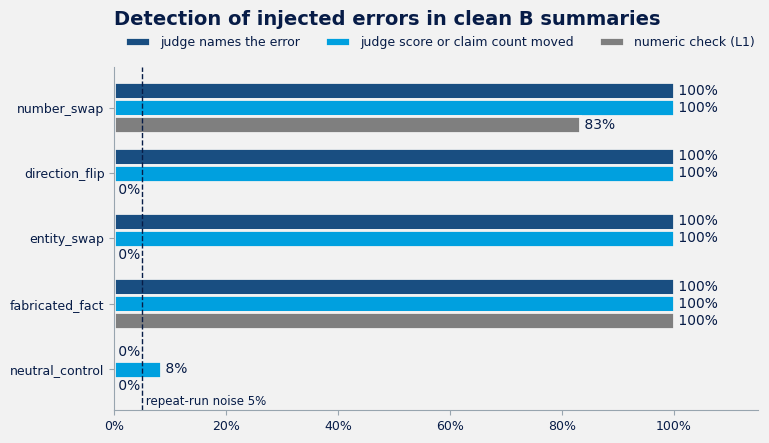

In [134]:
if READY:
    retest = run_retest(pw)
    meta = run_meta_eval(pw)
    save(retest, "judge_retest"); save(meta, "injected_errors")

    noise = retest.phantom_drop.mean()
    agree = pd.DataFrame({c: {"exact": (retest[c] == retest[c + "_2"]).mean(),
                              "within 1": ((retest[c] - retest[c + "_2"]).abs() <= 1).mean()} for c in CRITERIA}).T
    print(f"(a) Repeat-run noise: {noise:.0%} of identical summaries got a lower score or more claims on the second run.")
    display(agree.style.format("{:.0%}"))

    P_ORDER = ["number_swap", "direction_flip", "entity_swap", "fabricated_fact", "neutral_control"]
    mt = meta.groupby("perturbation").agg(n=("named", "size"), named_by_judge=("named", "mean"),
                                          judge_score_or_count_moved=("score_or_count_moved", "mean"),
                                          numeric_check=("numeric_check", "mean")).reindex(P_ORDER)
    print("(b) Injected errors (neutral_control = false alarms):")
    display(mt.style.format({c: "{:.0%}" for c in mt.columns if c != "n"}))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    y, h = np.arange(len(mt)), 0.26
    for k, (col, color, lab) in enumerate([("named_by_judge", MID_NAVY, "judge names the error"),
                                           ("judge_score_or_count_moved", CYAN, "judge score or claim count moved"),
                                           ("numeric_check", GRAY, "numeric check (L1)")]):
        bars = ax.barh(y + (k - 1) * h, mt[col], h, color=color, label=lab, **BAR)
        label_bars(ax, bars, "{:.0%}", horizontal=True)
    ax.axvline(noise, color=NAVY, ls="--", lw=1)
    ax.text(noise, len(mt) - 0.45, f" repeat-run noise {noise:.0%}", color=NAVY, fontsize=8.5)
    ax.set_yticks(y, mt.index); ax.invert_yaxis(); ax.set_xlim(0, 1.15)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=3)
    ax.set_title("Detection of injected errors in clean B summaries", pad=30)
    save_fig("07_evaluator_validation")

In [135]:
if READY and REVIEW_PATH.exists():
    review = pd.read_csv(REVIEW_PATH)
    jr = judge_pointwise(review[["item", "article_id", "ticker", "approach", "text"]], desc="judge on reviewed texts")
    m = review.merge(jr[["item"] + CRITERIA], on="item", suffixes=("_rev", "_judge"))
    rev_agree = pd.DataFrame({c: {"spearman_rho": stats.spearmanr(m[c + "_rev"], m[c + "_judge"])[0],
                                  "exact": (m[c + "_rev"] == m[c + "_judge"]).mean(),
                                  "within 1": ((m[c + "_rev"] - m[c + "_judge"]).abs() <= 1).mean()} for c in CRITERIA}).T
    # Direction agreement: for each article and criterion, do reviewer and judge agree on sign(B - A)?
    wide_r = m.pivot_table(index="article_id", columns="approach", values=[c + s for c in CRITERIA for s in ("_rev", "_judge")])
    rev_agree["same A-vs-B direction"] = [
        (np.sign(wide_r[(c + "_rev", "B_structured")] - wide_r[(c + "_rev", "A_simple")]) ==
         np.sign(wide_r[(c + "_judge", "B_structured")] - wide_r[(c + "_judge", "A_simple")])).mean() for c in CRITERIA]
    print(f"(c) Independent review of {len(m)} blinded summaries ({m.article_id.nunique()} articles):")
    display(rev_agree.style.format({"spearman_rho": "{:.2f}", "exact": "{:.0%}", "within 1": "{:.0%}", "same A-vs-B direction": "{:.0%}"}))
    display(m.groupby("approach")[[c + s for c in CRITERIA for s in ("_rev", "_judge")]].mean().round(2).T)

  judge on reviewed texts: 20/24
  judge on reviewed texts: 24/24
(c) Independent review of 24 blinded summaries (12 articles):


,spearman_rho,exact,within 1,same A-vs-B direction
faithfulness,0.92,75%,100%,92%
ticker_focus,0.83,79%,100%,92%
coverage,0.40,54%,100%,58%
conciseness,0.39,33%,96%,25%


approach,A_simple,B_structured
faithfulness_rev,3.00,5.00
faithfulness_judge,2.83,4.83
ticker_focus_rev,3.75,4.92
ticker_focus_judge,4.08,5.00
coverage_rev,4.75,4.75
coverage_judge,4.42,4.33
conciseness_rev,2.92,4.08
conciseness_judge,3.75,3.92


**How to read §4.4**
* **Repeat-run noise** is the floor. A difference smaller than this is not evidence.
* **Injected errors.** "Names the error" is the strict test: the judge must pinpoint the error, not merely lower a score. Where the judge misses a class, look at whether the numeric check catches it. The two layers are designed to complement each other.
* **Independent review.** The reviewer's ratings were **drafted by an AI assistant (Claude) acting as a senior analyst, working from the same rubric, and then reviewed by the author**. This checks consistency with a second rater. It is not a substitute for independent human raters, and because the reviewer comes from the same model family as the judge, their errors may be correlated (see Limitations). For the decision, the key column is **same A-vs-B direction**.

### 4.5 L1: deterministic checks

In [136]:
if READY:
    l1 = summaries.groupby("approach").agg(
        words_mean=("words", "mean"), numeric_precision=("numeric_precision", "mean"),
        share_with_unsupported_figure=("n_unsupported_numbers", lambda s: (s > 0).mean()),
        swapped_pairs=("n_swapped_pairs", "sum"), valid_output=("parse_ok", "mean"))
    display(l1.style.format({"words_mean": "{:.0f}", "numeric_precision": "{:.1%}",
                             "share_with_unsupported_figure": "{:.1%}", "valid_output": "{:.0%}"}))
    flagged = summaries[summaries.n_unsupported_numbers > 0].explode("unsupported_numbers")
    flagged["class"] = [classify_unsupported(f, ART.loc[(r.article_id, r.ticker)].model_input)
                        for f, r in zip(flagged.unsupported_numbers, flagged.itertuples())]
    print(f"{len(flagged)} figures in {flagged.index.nunique()} summaries not found in the source:")
    display(flagged[["article_id", "ticker", "approach", "unsupported_numbers", "class", "text"]])

,words_mean,numeric_precision,share_with_unsupported_figure,swapped_pairs,valid_output
approach,,,,,
A_simple,96,98.0%,6.1%,0,100%
B_structured,62,99.5%,2.0%,0,100%


4 figures in 4 summaries not found in the source:


,article_id,ticker,approach,unsupported_numbers,class,text
22,6,NVDA,A_simple,2026,year not in article,"Nvidia beat Q3 expectations and shares rose ~5% premarket, with CEO Jensen Huang dismissing AI-bubble fears as a ""ti..."
33,26,SCHW,A_simple,"$2,000",derivable,"Charles Schwab announced it will match the U.S. government's one-time $1,000 contribution for eligible newborn child..."
40,4,XOM,A_simple,2023,year not in article,"Exxon Mobil is exploring acquisitions of sanctioned Lukoil's international assets, joining Chevron and other bidders..."
69,1,NVDA,B_structured,"48,661.52",derivable,[NVDA relevance: secondary | sentiment: negative]\nNikkei fell 3% amid tech selloff following Wall Street's decline;...


### 4.6 L2: relevance triage vs human labels

Exact accuracy 84% | within one level 100% | overstated (gold peripheral/none → predicted primary/secondary): 5/13


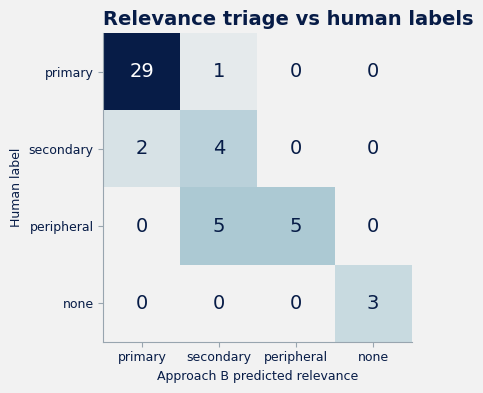

,article_id,ticker,gold_relevance,pred_relevance,summary_field
7,38,AAPL,primary,secondary,"Chase confirmed it will become the new issuer of the Apple Card, continuing features like up to 3% Daily Cash back a..."
18,47,JPM,peripheral,secondary,Bank stocks fell broadly amid concerns over Trump's proposed credit-card interest rate cap; JPMorgan executives warn...
20,1,NVDA,peripheral,secondary,Nikkei fell 3% amid tech selloff following Wall Street's decline; investors braced for Nvidia's earnings report due ...
21,5,NVDA,secondary,primary,Nvidia's earnings beat and strong revenue forecast drove a global stock rally. Shares rose 5.1% after-hours as CEO J...
23,7,NVDA,secondary,primary,Nvidia surged 4.9% premarket after forecasting Q4 sales above analyst estimates and beating Q3 revenue expectations....
32,25,SCHW,peripheral,secondary,"In a roundup of research actions, Morgan Stanley raised its price target on Charles Schwab Corp to $148.00 from $139..."
43,17,XOM,peripheral,secondary,U.S. Treasury rejected a Xtellus-led bid for Lukoil's foreign assets (~$22 billion). Exxon Mobil remains one of seve...
44,18,XOM,peripheral,secondary,Energy sector fell broadly (-2.4%) as WTI crude dropped 3.10% to $55.06/bbl on hopes for a Russia-Ukraine peace deal...


In [137]:
if READY:
    b = summaries[summaries.approach == "B_structured"].merge(articles[["article_id", "ticker", "gold_relevance"]], on=["article_id", "ticker"])
    lvl = {k: i for i, k in enumerate(REL_ORDER)}
    acc = (b.gold_relevance == b.pred_relevance).mean()
    within1 = (abs(b.gold_relevance.map(lvl) - b.pred_relevance.map(lvl)) <= 1).mean()
    low, high = b.gold_relevance.isin(["peripheral", "none"]), b.pred_relevance.isin(["primary", "secondary"])
    over = int((low & high).sum())
    print(f"Exact accuracy {acc:.0%} | within one level {within1:.0%} | "
          f"overstated (gold peripheral/none → predicted primary/secondary): {over}/{int(low.sum())}")
    cm = pd.crosstab(b.gold_relevance, b.pred_relevance).reindex(index=REL_ORDER, columns=REL_ORDER, fill_value=0)

    fig, ax = plt.subplots()
    ax.imshow(cm.values, cmap=LinearSegmentedColormap.from_list("s", [SCHWAB_BACKGROUND, LIGHT_BLUE, TEAL, NAVY]))
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm.values[i, j] > cm.values.max() / 2 else NAVY)
    ax.set_xticks(range(4), REL_ORDER); ax.set_yticks(range(4), REL_ORDER)
    ax.set_xlabel("Approach B predicted relevance"); ax.set_ylabel("Human label")
    ax.set_title("Relevance triage vs human labels")
    save_fig("08_relevance_confusion")
    display(b[b.gold_relevance != b.pred_relevance][["article_id", "ticker", "gold_relevance", "pred_relevance", "summary_field"]])

### 4.7 L3: rubric scores, paired comparison

,n,mean_A,mean_B,diff_B_minus_A,ci_low,ci_high,wilcoxon_p,B_better,A_better,same
faithfulness,49,2.80,4.43,+1.63,+1.35,+1.90,0.000,42,1,6
ticker_focus,49,3.88,4.78,+0.90,+0.61,+1.20,0.000,28,1,20
coverage,49,4.29,4.24,-0.04,-0.24,+0.16,0.750,10,12,27
conciseness,49,3.49,3.92,+0.43,+0.12,+0.71,0.008,24,7,18
n_unsupported_claims,49,3.22,0.71,-2.51,-2.94,-2.06,0.000,1,43,5
n_material_claims,49,0.84,0.00,-0.84,-1.14,-0.55,0.000,0,22,27
overstates_ticker_link,49,0.29,0.02,-0.27,-0.39,-0.14,0.000,0,13,36


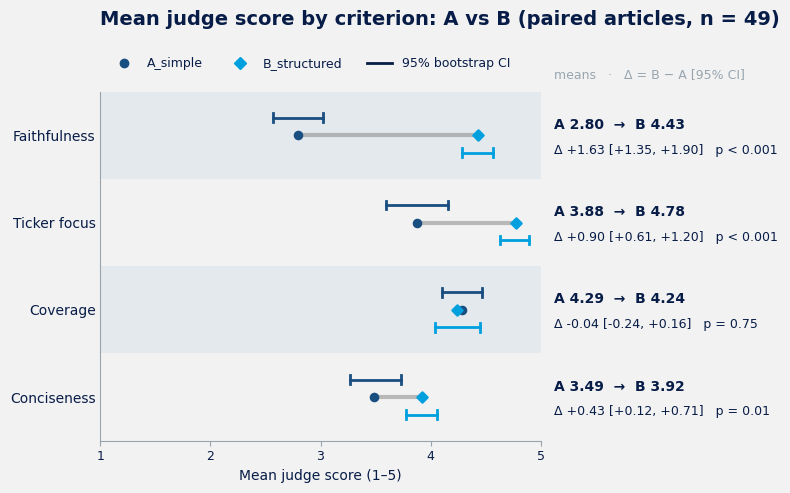

In [138]:
if READY:
    metrics = CRITERIA + ["n_unsupported_claims", "n_material_claims", "overstates_ticker_link"]
    wj = pw.pivot_table(index=["article_id", "ticker"], columns="approach", values=metrics, aggfunc="first")
    comp = pd.DataFrame({m: paired_comparison(wj[(m, "A_simple")], wj[(m, "B_structured")]) for m in metrics}).T
    count_cols = ["n", "B_better", "A_better", "same"]
    comp[count_cols] = comp[count_cols].astype(int)
    comp.to_csv(OUTPUT_DIR / "paired_comparison.csv")
    display(comp.style.format({"mean_A": "{:.2f}", "mean_B": "{:.2f}", "diff_B_minus_A": "{:+.2f}",
                               "ci_low": "{:+.2f}", "ci_high": "{:+.2f}", "wilcoxon_p": "{:.3f}"}))

    # Dumbbell: one band per criterion; A (circle) and B (diamond) on the same row; CIs just above / below.
    LABELS = {"faithfulness": "Faithfulness", "ticker_focus": "Ticker focus", "coverage": "Coverage", "conciseness": "Conciseness"}
    MARKERS = {"A_simple": "o", "B_structured": "D"}
    CI_OFFSET = {"A_simple": -0.2, "B_structured": +0.2}
    fig, ax = plt.subplots(figsize=(8, 5))
    for i, c in enumerate(CRITERIA):
        pair_c = wj[c].dropna()
        if i % 2 == 0:
            ax.axhspan(i - 0.5, i + 0.5, color="#E4E9ED", zorder=0)
        ci = {ap: bootstrap_mean_ci(pair_c[ap]) for ap in ["A_simple", "B_structured"]}
        ax.plot([ci["A_simple"][0], ci["B_structured"][0]], [i, i], color=GRAY, lw=3, alpha=0.5, solid_capstyle="butt", zorder=1)
        for ap in ["A_simple", "B_structured"]:
            mean, lo, hi = ci[ap]
            yc = i + CI_OFFSET[ap]
            ax.plot([lo, hi], [yc, yc], color=APPROACH_COLORS[ap], lw=2, zorder=2)
            ax.plot([lo, lo], [yc - 0.05, yc + 0.05], color=APPROACH_COLORS[ap], lw=2, zorder=2)
            ax.plot([hi, hi], [yc - 0.05, yc + 0.05], color=APPROACH_COLORS[ap], lw=2, zorder=2)
            ax.scatter(mean, i, marker=MARKERS[ap], s=26, color=APPROACH_COLORS[ap], linewidth=1.8, zorder=3)
        r = comp.loc[c]
        p_txt = "p < 0.001" if r.wilcoxon_p < 0.001 else f"p = {r.wilcoxon_p:.2f}"
        ax.text(5.12, i - 0.12, f"A {r.mean_A:.2f}  →  B {r.mean_B:.2f}", va="center", fontsize=10, color=NAVY, fontweight="bold")
        ax.text(5.12, i + 0.17, f"Δ {r.diff_B_minus_A:+.2f} [{r.ci_low:+.2f}, {r.ci_high:+.2f}]   {p_txt}", va="center", fontsize=9, color=NAVY)
    ax.set_yticks(range(len(CRITERIA)), [LABELS[c] for c in CRITERIA], fontsize=10)
    ax.set_ylim(len(CRITERIA) - 0.5, -0.5)
    ax.set_xlim(1, 5); ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_xlabel("Mean judge score (1–5)", fontsize=10)
    ax.tick_params(axis="y", length=0)
    ax.text(5.12, -0.62, "means   ·   Δ = B − A [95% CI]", fontsize=9, color=SCHWAB_SECONDARY_TEXT, va="bottom")
    handles = [plt.Line2D([], [], marker=MARKERS[a], color=APPROACH_COLORS[a], linestyle="none", markersize=6)
               for a in ["A_simple", "B_structured"]] + [plt.Line2D([], [], color=NAVY, lw=2)]
    ax.legend(handles, ["A_simple", "B_structured", "95% bootstrap CI"], loc="lower left", bbox_to_anchor=(0, 1.03), ncol=3)
    ax.set_title(f"Mean judge score by criterion: A vs B (paired articles, n = {comp.loc['faithfulness', 'n']})", pad=48)
    save_fig("09_judge_scores")

### 4.8 L4: pairwise preference with order swap

Order-consistent verdicts: 98% | first-shown summary won 49% of calls (50% = no position bias) | sign test on decisive verdicts p = 1.31e-10


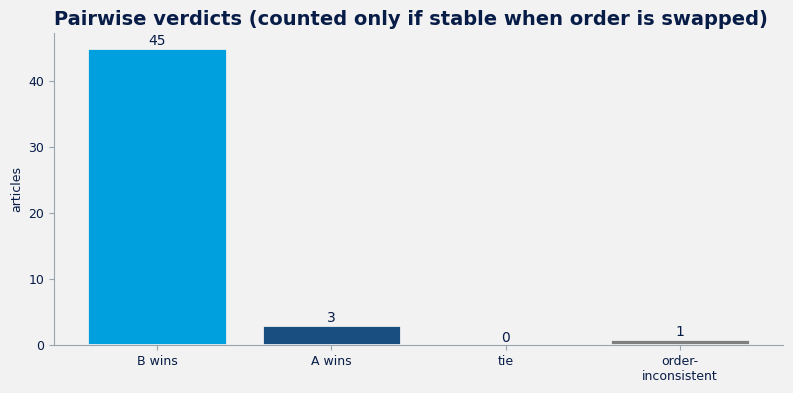

verdict,A,B,inconsistent
gold_relevance,,,
primary,3,26,1
secondary,0,6,0
peripheral,0,10,0
none,0,3,0


In [139]:
if READY:
    vc = pair.verdict.value_counts().reindex(["B", "A", "tie", "inconsistent"], fill_value=0)
    first_pos = pd.concat([pair.first_shown_won_1, pair.first_shown_won_2]).mean()
    decisive = int(vc["A"] + vc["B"])
    sign_p = stats.binomtest(int(vc["B"]), decisive, 0.5).pvalue if decisive else np.nan
    print(f"Order-consistent verdicts: {(pair.verdict != 'inconsistent').mean():.0%} | first-shown summary won "
          f"{first_pos:.0%} of calls (50% = no position bias) | sign test on decisive verdicts p = {sign_p:.3g}")

    fig, ax = plt.subplots()
    cols = {"B": CYAN, "A": MID_NAVY, "tie": LIGHT_BLUE, "inconsistent": GRAY}
    bars = ax.bar(vc.index, vc.values, color=[cols[k] for k in vc.index], **BAR)
    label_bars(ax, bars)
    ax.set_xticks(range(4), ["B wins", "A wins", "tie", "order-\ninconsistent"])
    ax.set_title("Pairwise verdicts (counted only if stable when order is swapped)")
    ax.set_ylabel("articles")
    save_fig("10_pairwise")
    ps = pair.merge(articles[["article_id", "ticker", "gold_relevance"]], on=["article_id", "ticker"])
    display(pd.crosstab(ps.gold_relevance, ps.verdict).reindex(REL_ORDER))

### 4.9 Where do the approaches differ? (slices for H1–H3)

n  faithfulness  unsupported_claims  material_claims  ticker_focus  coverage  overstates_link
slice                                     approach                                                                                                    
peripheral / unrelated to ticker          A_simple      12          2.67                3.58             1.00          2.83      3.83             0.75
                                          B_structured  12          4.25                0.92             0.00          4.58      3.75             0.08
substantive, ticker-relevant              A_simple      26          2.92                2.96             0.85          4.27      4.31             0.12
                                          B_structured  26          4.31                0.88             0.00          4.77      4.15             0.00
thin input (headline-only / analyst note) A_simple      11          2.64                3.45             0.64          4.09      4.73             0.18
                                          B_structured  11          4.91                0.09             0.00          5.00      5.00             0.00

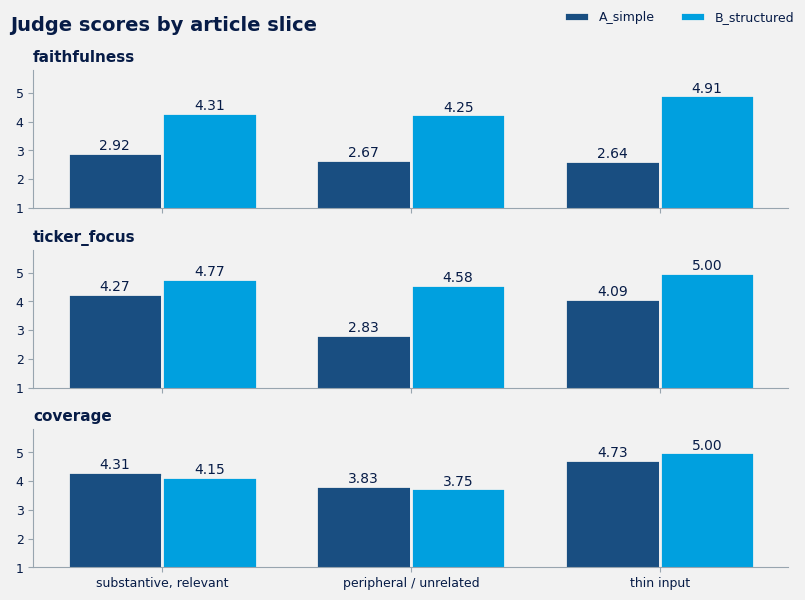

In [140]:
if READY:
    SLICES = ["substantive, ticker-relevant", "peripheral / unrelated to ticker", "thin input (headline-only / analyst note)"]
    pw["slice"] = np.select([pw.body_type.isin(["title_only", "analyst_note"]), pw.gold_relevance.isin(["peripheral", "none"])],
                            [SLICES[2], SLICES[1]], SLICES[0])
    sl = pw.groupby(["slice", "approach"]).agg(n=("faithfulness", "size"), faithfulness=("faithfulness", "mean"),
                                                unsupported_claims=("n_unsupported_claims", "mean"),
                                                material_claims=("n_material_claims", "mean"),
                                                ticker_focus=("ticker_focus", "mean"), coverage=("coverage", "mean"),
                                                overstates_link=("overstates_ticker_link", "mean")).round(2)
    sl.to_csv(OUTPUT_DIR / "slice_results.csv")
    display(sl)

    fig, axes = plt.subplots(3, 1, sharex=True, figsize=(8, 6))
    for ax, metric in zip(axes, ["faithfulness", "ticker_focus", "coverage"]):
        x, w = np.arange(len(SLICES)), 0.38
        for k, ap in enumerate(["A_simple", "B_structured"]):
            vals = [pw[(pw.slice == s) & (pw.approach == ap)][metric].mean() for s in SLICES]
            bars = ax.bar(x + (k - 0.5) * w, vals, w, color=APPROACH_COLORS[ap], label=ap, **BAR)
            label_bars(ax, bars, "{:.2f}")
        ax.set_ylim(1, 5.8); ax.set_title(metric, fontsize=11)
    axes[-1].set_xticks(np.arange(len(SLICES)), ["substantive, relevant", "peripheral / unrelated", "thin input"])
    h_, l_ = axes[0].get_legend_handles_labels()
    fig.legend(h_, l_, loc="upper right", ncol=2)
    fig.suptitle("Judge scores by article slice", x=0.01, ha="left", fontweight="bold", color=NAVY, fontsize=14)
    save_fig("11_slices")

### 4.10 Why? What kinds of errors each approach makes

Unsupported claims per summary, by type:


type,outside_fact,wrong_detail,unattributed,speculation
approach,,,,
A_simple,0.45,0.39,0.24,2.14
B_structured,0.00,0.16,0.16,0.39


type         outside_fact       speculation       unattributed       wrong_detail      
severity         material minor    material minor     material minor     material minor
approach                                                                               
A_simple                5    17          31    74            3     9            2    17
B_structured            0     0           0    19            0     8            0     8

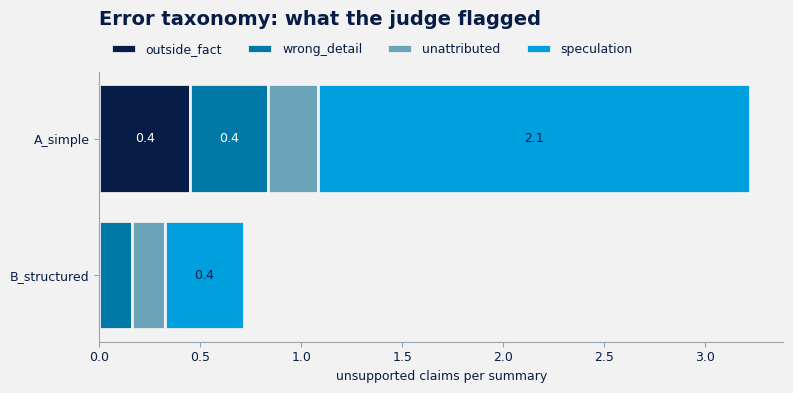

**A_simple: material claims (first 4)**
* #12 [outside_fact] The executive order would establish a single, unified federal AI regulatory standard aiming to preempt the current patchwork of state-level AI regulations
* #12 [speculation] For Apple investors, this move could reduce regulatory complexity and compliance costs across state lines for AI products including Apple Intelligence
* #12 [speculation] A unified national standard may accelerate innovation timelines, potentially benefiting Apple's ongoing AI development efforts
* #22 [speculation] potentially reducing Apple's commission revenue from Japanese app transactions

**B_structured: material claims (first 4)**


In [141]:
if READY:
    claims = pw[["article_id", "ticker", "approach", "unsupported_claims"]].explode("unsupported_claims").dropna()
    claims = pd.concat([claims.drop(columns="unsupported_claims").reset_index(drop=True),
                        pd.DataFrame(list(claims.unsupported_claims))], axis=1)
    n_sum = pw.groupby("approach").size()
    tax = claims.pivot_table(index="approach", columns=["type", "severity"], values="claim", aggfunc="count", fill_value=0)
    per = claims.pivot_table(index="approach", columns="type", values="claim", aggfunc="count", fill_value=0)
    per = per.reindex(columns=[t for t in CLAIM_TYPES if t in per.columns]).div(n_sum, axis=0)
    print("Unsupported claims per summary, by type:")
    display(per.round(2))
    display(tax)

    fig, ax = plt.subplots()
    type_colors = dict(zip(CLAIM_TYPES, [NAVY, TEAL, LIGHT_BLUE, CYAN]))
    left = np.zeros(len(per))
    for t in per.columns:
        bars = ax.barh(per.index, per[t], left=left, color=type_colors.get(t, GRAY), label=t, **BAR)
        for bb, v in zip(bars, per[t]):
            if v >= 0.25:
                ax.text(bb.get_x() + bb.get_width() / 2, bb.get_y() + bb.get_height() / 2, f"{v:.1f}",
                        ha="center", va="center", color="white" if t in ("outside_fact", "wrong_detail") else NAVY)
        left += per[t].values
    ax.invert_yaxis()
    ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.02))
    ax.set_xlabel("unsupported claims per summary")
    ax.set_title("Error taxonomy: what the judge flagged", pad=34)
    save_fig("12_error_taxonomy")

    for ap in ["A_simple", "B_structured"]:
        ex = claims[(claims.approach == ap) & (claims.severity == "material")].head(4)
        display(Markdown(f"**{ap}: material claims (first 4)**\n" + "\n".join(f"* #{r.article_id} [{r.type}] {r.claim}" for r in ex.itertuples())))

### 4.11 Robustness: is B's advantage just its header?
The judge sees B's `[relevance | sentiment]` header, which could inflate ticker focus by itself. Here B's summaries are re-judged with the header removed, then compared with A again.

In [142]:
if READY:
    b_body = summaries[summaries.approach == "B_structured"].assign(text=lambda d: d.text.map(summary_body))
    ab = judge_pointwise(b_body[["article_id", "ticker", "approach", "text"]], desc="B without header")
    a_ = pw[pw.approach == "A_simple"].set_index(["article_id", "ticker"])
    ab = ab.set_index(["article_id", "ticker"]).reindex(a_.index)
    abl = pd.DataFrame({m: paired_comparison(a_[m], ab[m]) for m in ["faithfulness", "ticker_focus", "n_unsupported_claims"]}).T
    display(abl[["n", "mean_A", "mean_B", "diff_B_minus_A", "ci_low", "ci_high", "wilcoxon_p"]].style.format(
        {c: "{:+.2f}" for c in ["diff_B_minus_A", "ci_low", "ci_high"]} | {"mean_A": "{:.2f}", "mean_B": "{:.2f}", "wilcoxon_p": "{:.3f}"}))

  B without header: 20/49
  B without header: 40/49
  B without header: 49/49


,n,mean_A,mean_B,diff_B_minus_A,ci_low,ci_high,wilcoxon_p
faithfulness,49.000000,2.80,4.47,+1.67,+1.37,+1.96,0.000
ticker_focus,49.000000,3.88,4.67,+0.80,+0.49,+1.12,0.000
n_unsupported_claims,49.000000,3.22,0.59,-2.63,-3.06,-2.20,0.000


### 4.12 Cost
Token usage by call type, from every response in the cache (including earlier runs).

In [143]:
if READY:
    recs = [json.loads(p.read_text()) for p in CACHE_DIR.glob("*.json")]
    kind = {SIMPLE_SYSTEM: "generate A", STRUCTURED_SYSTEM: "generate B", JUDGE_SYSTEM: "judge"}
    usage = pd.DataFrame([{"call": kind.get(r["system"], "other"), "input_tokens": r["usage"]["input"],
                           "output_tokens": r["usage"]["output"]} for r in recs])
    cost = usage.groupby("call").agg(calls=("input_tokens", "size"), mean_in=("input_tokens", "mean"),
                                     mean_out=("output_tokens", "mean"), total_in=("input_tokens", "sum"),
                                     total_out=("output_tokens", "sum")).round(0)
    display(cost)
    ga, gb = cost.loc["generate A"], cost.loc["generate B"]
    print(f"Per article, B uses {gb.mean_in / ga.mean_in:.1f}x A's input tokens and {gb.mean_out / ga.mean_out:.1f}x its output tokens.")

,calls,mean_in,mean_out,total_in,total_out
call,,,,,
generate A,49,686.0,232.0,33606,11378
generate B,98,1673.0,265.0,163930,25936
judge,593,1922.0,471.0,1139670,279256


Per article, B uses 2.4x A's input tokens and 1.1x its output tokens.


## 5. Analysis & Recommendations

### 5.1 Results at a glance
Every statement in the summary at the top and in §5.2 is checked against this run below. ✓ means the data supports it; ⚠ means revise the text.

In [144]:
if READY:
    c = comp
    glance = pd.DataFrame({
        "A": [f"{c.loc['faithfulness','mean_A']:.2f}", f"{c.loc['n_unsupported_claims','mean_A']:.2f}",
              f"{c.loc['n_material_claims','mean_A']:.2f}", f"{c.loc['ticker_focus','mean_A']:.2f}",
              f"{c.loc['overstates_ticker_link','mean_A']:.0%}", f"{c.loc['coverage','mean_A']:.2f}",
              f"{c.loc['conciseness','mean_A']:.2f}", f"{int(vc['A'])}", "—", f"{l1.loc['A_simple','numeric_precision']:.1%}"],
        "B": [f"{c.loc['faithfulness','mean_B']:.2f}", f"{c.loc['n_unsupported_claims','mean_B']:.2f}",
              f"{c.loc['n_material_claims','mean_B']:.2f}", f"{c.loc['ticker_focus','mean_B']:.2f}",
              f"{c.loc['overstates_ticker_link','mean_B']:.0%}", f"{c.loc['coverage','mean_B']:.2f}",
              f"{c.loc['conciseness','mean_B']:.2f}", f"{int(vc['B'])}", f"{acc:.0%} exact / {within1:.0%} ±1",
              f"{l1.loc['B_structured','numeric_precision']:.1%}"],
        "B − A [95% CI]": [f"{c.loc[m,'diff_B_minus_A']:+.2f} [{c.loc[m,'ci_low']:+.2f}, {c.loc[m,'ci_high']:+.2f}]" for m in
                           ["faithfulness", "n_unsupported_claims", "n_material_claims", "ticker_focus",
                            "overstates_ticker_link", "coverage", "conciseness"]] + [f"sign test p = {sign_p:.2g}", "", ""],
    }, index=["Faithfulness (1–5)", "Unsupported claims / summary", "Material claims / summary", "Ticker focus (1–5)",
              "Overstates ticker link", "Coverage (1–5)", "Conciseness (1–5)", "Pairwise wins (order-consistent)",
              "Relevance label vs human", "Numeric precision (L1)"])
    display(glance)

    per_t = per.reindex(columns=CLAIM_TYPES, fill_value=0)
    a_top = per_t.loc["A_simple"].idxmax()
    checks = [
        ("B is more faithful (CI of Δ above 0)", c.loc["faithfulness", "ci_low"] > 0),
        ("B has fewer unsupported claims (CI of Δ below 0)", c.loc["n_unsupported_claims", "ci_high"] < 0),
        ("B has fewer material claims (CI of Δ below 0)", c.loc["n_material_claims", "ci_high"] < 0),
        ("B is more ticker-focused (CI of Δ above 0)", c.loc["ticker_focus", "ci_low"] > 0),
        ("B overstates ticker links less (CI of Δ below 0)", c.loc["overstates_ticker_link", "ci_high"] < 0),
        ("No coverage cost for B (CI of Δ includes 0 or is above it)", c.loc["coverage", "ci_high"] >= 0),
        ("B wins the pairwise comparison (sign test p < 0.05)", vc["B"] > vc["A"] and sign_p < 0.05),
        ("Judge shows no position bias (first-shown wins 40–60%)", 0.4 <= first_pos <= 0.6),
        (f"A's most common error type is speculation or outside facts (observed: {a_top})", a_top in ("speculation", "outside_fact")),
        ("B's advantage survives removing its header (faithfulness and ticker focus CIs above 0)",
         abl.loc["faithfulness", "ci_low"] > 0 and abl.loc["ticker_focus", "ci_low"] > 0),
        ("Judge names fabricated facts and entity swaps above repeat-run noise",
         min(mt.loc["fabricated_fact", "named_by_judge"], mt.loc["entity_swap", "named_by_judge"]) > noise),
        ("Numeric check catches number swaps the judge may miss (≥ 80%)", mt.loc["number_swap", "numeric_check"] >= 0.8),
    ]
    b_words = summaries.groupby("approach").words.mean()
    rel_err = (b.gold_relevance + " → " + b.pred_relevance)[b.gold_relevance != b.pred_relevance]
    top_err = rel_err.value_counts().index[0] if len(rel_err) else "none"
    checks += [
        (f"B is shorter than A (mean words: A {b_words['A_simple']:.0f}, B {b_words['B_structured']:.0f})",
         b_words["B_structured"] < b_words["A_simple"]),
        (f"B's most common relevance error is peripheral → secondary (observed: {top_err})", top_err == "peripheral → secondary"),
        ("Every B output is valid JSON", bool(summaries[summaries.approach == "B_structured"].parse_ok.all())),
        ("No judge reply was truncated or unparseable", JUDGE.stats["truncated"] == 0 and pw.judge_error.isna().all()),
    ]
    if "rev_agree" in globals():
        checks.append(("Reviewer agrees with the judge on A-vs-B direction for faithfulness (≥ 75%)",
                       rev_agree.loc["faithfulness", "same A-vs-B direction"] >= 0.75))
    display(Markdown("\n".join(f"* {'✓' if ok else '⚠'} {txt}" for txt, ok in checks)))

    key = {"n_paired": int(c.loc["faithfulness", "n"]), "comparison": c.round(4).to_dict(orient="index"),
           "pairwise": vc.to_dict(), "first_shown_win_rate": float(first_pos), "relevance_accuracy": float(acc),
           "repeat_run_noise": float(noise), "checks": {t: bool(ok) for t, ok in checks}}
    (OUTPUT_DIR / "key_results.json").write_text(json.dumps(key, indent=2, default=float))

,A,B,B − A [95% CI]
Faithfulness (1–5),2.80,4.43,"+1.63 [+1.35, +1.90]"
Unsupported claims / summary,3.22,0.71,"-2.51 [-2.94, -2.06]"
Material claims / summary,0.84,0.00,"-0.84 [-1.14, -0.55]"
Ticker focus (1–5),3.88,4.78,"+0.90 [+0.61, +1.20]"
Overstates ticker link,29%,2%,"-0.27 [-0.39, -0.14]"
Coverage (1–5),4.29,4.24,"-0.04 [-0.24, +0.16]"
Conciseness (1–5),3.49,3.92,"+0.43 [+0.12, +0.71]"
Pairwise wins (order-consistent),3,45,sign test p = 1.3e-10
Relevance label vs human,—,84% exact / 100% ±1,
Numeric precision (L1),98.0%,99.5%,


* ✓ B is more faithful (CI of Δ above 0)
* ✓ B has fewer unsupported claims (CI of Δ below 0)
* ✓ B has fewer material claims (CI of Δ below 0)
* ✓ B is more ticker-focused (CI of Δ above 0)
* ✓ B overstates ticker links less (CI of Δ below 0)
* ✓ No coverage cost for B (CI of Δ includes 0 or is above it)
* ✓ B wins the pairwise comparison (sign test p < 0.05)
* ✓ Judge shows no position bias (first-shown wins 40–60%)
* ✓ A's most common error type is speculation or outside facts (observed: speculation)
* ✓ B's advantage survives removing its header (faithfulness and ticker focus CIs above 0)
* ✓ Judge names fabricated facts and entity swaps above repeat-run noise
* ✓ Numeric check catches number swaps the judge may miss (≥ 80%)
* ✓ B is shorter than A (mean words: A 96, B 62)
* ✓ B's most common relevance error is peripheral → secondary (observed: peripheral → secondary)
* ✓ Every B output is valid JSON
* ✓ No judge reply was truncated or unparseable
* ✓ Reviewer agrees with the judge on A-vs-B direction for faithfulness (≥ 75%)

### 5.2 What worked, what didn't, and why

**What worked**
1. **Explicit grounding rules made B far more faithful.** B's gain is concentrated where A's errors are: *speculation* ("signals continued confidence…", "could weigh on…") and *outside facts* (the prior Apple Card issuer, product names, years the article never gives). The mechanism is the prompt:
   * A's persona ("a financial analyst", "for an investor who follows…") invites value-adding interpretation, and nothing forbids it.
   * On thin inputs, a 100-word budget gets filled with inference.
   * Many of these statements are *true* in the world, but the article doesn't support them, so an analyst can't verify them from the source. In research, **traceability** is the requirement, not just truth.
2. **Relevance triage fixed the dataset's main failure mode.** On peripheral and unrelated articles, A routinely turns a market wrap into a story about the ticker. B labels relevance and stays within what the article says about the ticker (H1).
3. **Structure cost no coverage (H3 not supported).** B is roughly 40% shorter and loses no measurable coverage. A's extra words are mostly interpretation, not facts.
4. **Thin inputs are where the difference is largest (H2).** Headline-only items and analyst notes give A the most room to pad; B's "limited information" path removes the incentive.
5. **The layered evaluation paid for itself:**
   * The numeric check exposed its *own* false alarms: the wire's `Percent Change` field, since fixed.
   * The judge's claim lists turned scores into auditable evidence, which the error taxonomy (§4.10) is built from.
   * The order swap showed the pairwise verdicts are not a position artifact.

**What didn't work, or only partly**
1. **Relevance triage over-rates market wraps.** B's most common labelling error is calling a *peripheral* article *secondary* (§4.6). The line between "one of several subjects" and "mentioned in passing" is fuzzy for wraps where the ticker gets one sentence. Clearer definitions or worked examples are the next step.
2. **B still makes errors,** mostly *minor* ones: a dropped "sources say" in the lead sentence, a tense shift ("becomes" vs "will become"). The grounding rule reduces errors; it doesn't eliminate them.
3. **B's key facts often repeat its summary,** so conciseness did not improve despite the shorter text.
4. **The judge is good but not complete.** It doesn't name every injected error (§4.4), and repeat runs of identical text show some noise. A small numeric change is exactly what the deterministic check catches and the judge can miss, which is why neither layer should be used alone.
5. **The first run exposed engineering issues** that are now fixed:
   * 19 judge replies were truncated at 1,200 tokens (10 unparseable); fixed by a larger budget and structured output.
   * 2 of B's replies were invalid JSON; fixed by structured outputs.

### 5.3 Recommendations
1. **Adopt B's design:** ticker-conditioned input, explicit grounding rules, relevance triage, and schema-constrained output. Use the relevance label to filter or down-rank items *before* anyone reads a summary.
2. **Make traceability a requirement.** Every statement must be supported by the article; any interpretation must be labelled as such. Add claim-level source citations as the next step, so each sentence links to the passage behind it.
3. **Treat thin inputs as their own class.** Parse template wires, such as price-target changes, with rules instead of an LLM. Return "limited information" rather than padding.
4. **Evaluate in layers, and validate the evaluator:**
   * Deterministic numeric checks on 100% of output.
   * An LLM judge that enumerates claims before scoring, on a sample.
   * Order-swapped pairwise comparisons for decisions between versions.
   * Injected-error and repeat-run tests whenever the judge or its prompt changes.

### 5.4 Limitations
* **Small sample:** n = 49 articles across 5 tickers and 2 months. Effects are large, but the CIs are wide and per-slice results rest on 11–26 articles.
* **One model family:** the generator, judge and reviewer are all Claude models. Self-preference affects both approaches equally, but a cross-provider judge is the stronger control.
* **The independent review is AI-drafted,** so it is not independent human judgment. The relevance labels come from one annotator.
* **Stochastic outputs:** no temperature control is available, so outputs vary between runs. Results are reproducible from the cache, and §4.4 quantifies the judge's noise.
* **Synthetic errors** in §4.4 are cleaner than natural ones.
* **Coverage is judged without a reference,** so "missing facts" reflects the judge's notion of importance.

### 5.5 Next steps
1. **Human calibration.** Two analysts independently rate ~50 summaries; measure inter-rater agreement; calibrate the judge against them.
2. **Cross-provider judging:** a judge from a different model family, or a panel, to remove same-family bias.
3. **Sharper triage.** Worked examples for the secondary/peripheral boundary. Optionally, a small fine-tuned classifier for relevance and sentiment: fine-tuned small models beat prompted large models on narrow financial classification (e.g. FinNLP-2024, LLaMA-3-8B + QLoRA).
4. **Why not an open, fine-tuned summarizer?** Public ones (PEGASUS fine-tuned on Bloomberg news; LLaMA-3-8B fine-tuned on EDTSum) optimise ROUGE against generic one-sentence references and cannot be told which ticker matters. They could be added as Approach C in this same framework; they are candidates for cheap triage, not for summaries.
5. **Production at ~50,000 articles/day:**
   * Group duplicate stories and summarize each story once.
   * Identify companies with entity linking instead of trusting feed tags.
   * Triage with cheap models; send only relevant, material items to the LLM.
   * Deliver per-ticker digests rather than 50,000 paragraphs.
   * Run deterministic checks on 100% of output and the validated judge on a daily sample.
   * Keep a full audit trail and clear content licensing before sending articles to a third-party API.